# TP Integrador · Python para Ciencia de Datos
## Predicción de contratación de plazos fijos — Regresión Logística y Random Forest

**Integrantes:** Leandro Ezequiel Galante, Martín Ivan Remmer, Lucas Lacerda Piccinna, Jonathan Lucas Caceres Andia y Alejo Tabasco  
**Materia:** Python para Ciencia de Datos · UADE  
**Datos:** [Bank Marketing, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/222/bank+marketing) — `bank-full.csv`.

### Problema que queremos resolver

Un banco realizó campañas telefónicas para ofrecer depósitos a plazo fijo. De cada contacto sabemos si el cliente contrató (`y = yes`) o no (`y = no`). Queremos estimar **a quién conviene contactar primero, usando solo información disponible antes de la llamada**.

Vamos a describir los datos, comprobar su calidad y comparar un predictor que siempre dice «no» (baseline) con cuatro métodos: Regresión Lineal, KNN, Regresión Logística y Random Forest. Los dos últimos serán los modelos principales: primero analizaremos **Regresión Logística**, después **Random Forest** y por último los compararemos con el mismo conjunto de prueba.

En los dos modelos principales probaremos distintos hiperparámetros con **validación cruzada sobre entrenamiento**. Recién después de elegir una configuración miraremos los resultados finales en test.

> **Criterio:** como solo una minoría contrata, no vamos a elegir modelos por accuracy únicamente. Daremos importancia a la **precisión media (Average Precision / PR-AUC)**, que evalúa qué tan bien ordenamos a los posibles contratantes, y también revisaremos recall, precision, F1 y errores de clasificación.

**Recorrido:** 1. Datos → 2. Calidad → 3. EDA univariado → 4. EDA bivariado → 5. Preparación → 6. Modelos iniciales → 7. Regresión Logística → 8. Random Forest → 9. Comparación → 10. Conclusiones.

### Diccionario de variables

| Variable | Tipo | Descripción |
|---|---|---|
| `age` | numérica | Edad del cliente |
| `job` | categórica | Tipo de trabajo |
| `marital` | categórica | Estado civil |
| `education` | categórica | Nivel educativo (primary / secondary / tertiary) |
| `default` | categórica | ¿Tiene créditos en mora? |
| `balance` | numérica | Saldo promedio anual en la cuenta (euros) |
| `housing` | categórica | ¿Tiene crédito hipotecario? |
| `loan` | categórica | ¿Tiene préstamo personal? |
| `contact` | categórica | Medio de contacto (celular / fijo) |
| `day`, `month` | numérica / categórica | Día y mes del último contacto (no hay año) |
| `duration` | numérica | Duración de la última llamada, en segundos |
| `campaign` | numérica | Cantidad de contactos en **esta** campaña (incluye el último) |
| `pdays` | numérica | Días desde el último contacto de una campaña **anterior** (-1 = nunca contactado) |
| `previous` | numérica | Cantidad de contactos en campañas anteriores |
| `poutcome` | categórica | Resultado de la campaña anterior |
| **`y`** | **categórica (objetivo)** | **¿Contrató el plazo fijo? (yes / no)** |

## 0. Librerías y configuración

In [1]:
# Análisis de datos
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Modelado y evaluación
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, classification_report)
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMILLA = 42
sns.set_theme(style="whitegrid")
COLOR_NO, COLOR_SI = "#8FA3BF", "#C9661A"
PALETA_Y = {"no": COLOR_NO, "yes": COLOR_SI}
pd.set_option("display.max_columns", 30)

## 1. Carga de datos
El archivo `bank-full.csv` (UCI Bank Marketing) usa **punto y coma** como separador, por eso lo indicamos con `sep=";"`. Tiene que estar en la misma carpeta que el notebook (se puede descargar desde el link de la portada).

In [2]:
df_raw = pd.read_csv("bank-full.csv", sep=";")
print(f"Datos originales: {df_raw.shape[0]:,} filas y {df_raw.shape[1]} columnas.")
display(df_raw.head())

Datos originales: 45,211 filas y 17 columnas.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Trabajamos sobre una copia (`df`) para no modificar los datos originales.

In [3]:
df = df_raw.copy()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


**Lectura:** 45.211 clientes y 17 columnas (7 numéricas y 10 categóricas).

## 2. Calidad de los datos
Revisamos **tipos de datos, nulos, duplicados y valores imposibles o sospechosos**, y para cada problema dejamos registrada la decisión y el motivo.

### 2.1 Tipos de datos

In [4]:
df.dtypes.to_frame("tipo").T

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
tipo,int64,str,str,str,str,int64,str,str,str,int64,str,int64,int64,int64,int64,str,str


Los tipos son correctos: las variables numéricas se leyeron como enteros (`int64`) y las categóricas como texto (`object`; en pandas 3 aparece como `str`). `month` es texto (`jan`, `feb`, …): más adelante la convertimos en una **categoría ordenada** para que los gráficos respeten el orden del calendario.

### 2.2 Valores nulos

In [5]:
df.isna().sum().to_frame("nulos").T

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
nulos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


No encontramos nulos `NaN`, pero varias variables contienen el texto `unknown`. Lo contamos por separado antes de decidir cómo tratarlo:

In [6]:
cat_cols = df.select_dtypes(exclude="number").columns
unknown = (df[cat_cols] == "unknown").sum()
unknown = unknown[unknown > 0].to_frame("cantidad")
unknown["porcentaje"] = (unknown["cantidad"] / len(df) * 100).round(1)
unknown.sort_values("cantidad", ascending=False)

,cantidad,porcentaje
poutcome,36959,81.7
contact,13020,28.8
education,1857,4.1
job,288,0.6


**Decisión:** conservamos `unknown` como una categoría. No es lo mismo un valor desconocido que uno ausente de manera aleatoria.

- En `poutcome` es frecuente porque no hay un resultado registrado de una campaña anterior. Eliminar esos registros nos dejaría con una muestra mucho más pequeña y posiblemente sesgada.
- En `contact` puede reflejar cambios en la forma de registrar llamadas; lo mantenemos para el análisis exploratorio.
- En `education` y `job` preferimos no inventar datos imputando la categoría mayoritaria.

Cuando entrenemos los modelos, las variables categóricas seleccionadas se codificarán mediante *one-hot encoding*.

### 2.3 Duplicados

In [7]:
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 0


No hay filas duplicadas, así que no hay nada que eliminar.

### 2.4 Valores imposibles o sospechosos
Revisamos el rango de cada variable numérica y lo comparamos con lo que tiene sentido en el dominio:

In [8]:
rangos = df.describe().T[["min", "max"]]
rangos["rango esperado"] = ["18 a ~100 años", "puede ser negativo (descubierto)", "1 a 31",
                            ">= 0 segundos", ">= 1 (incluye el último contacto)",
                            "-1 (nunca) o >= 0 días", ">= 0"]
rangos

,min,max,rango esperado
age,18.0,95.0,18 a ~100 años
balance,-8019.0,102127.0,puede ser negativo (descubierto)
day,1.0,31.0,1 a 31
duration,0.0,4918.0,>= 0 segundos
campaign,1.0,63.0,>= 1 (incluye el último contacto)
pdays,-1.0,871.0,-1 (nunca) o >= 0 días
previous,0.0,275.0,>= 0


- `age` (18–95), `day` (1–31) y `campaign` (≥ 1) están dentro de rangos válidos.
- `balance` negativo **no es un error**: es un cliente con la cuenta en descubierto. Lo conservamos.
- `pdays = -1` es un **código**, no una cantidad de días: significa "nunca contactado antes". Lo comprobamos:

In [9]:
nunca_contactado = df["pdays"] == -1
print("pdays == -1 coincide con previous == 0 en todas las filas:",
      (nunca_contactado == (df["previous"] == 0)).all())
pd.crosstab(nunca_contactado, df["poutcome"]).rename_axis(index="pdays == -1")

pdays == -1 coincide con previous == 0 en todas las filas: True


poutcome,failure,other,success,unknown
pdays == -1,,,,
False,4901,1840,1511,5
True,0,0,0,36954


La salida confirma que `pdays = -1` coincide **exactamente** con `previous = 0`, y casi siempre con `poutcome = unknown` (salvo 5 casos): las tres columnas registran el mismo hecho, si el cliente fue contactado en una campaña anterior.

**Decisión:** creamos `contactado_antes` (1 si hubo contacto previo) y **no usamos `pdays` en el modelo**. Su `-1` es un código y no una cantidad de días: mezclado con valores reales (0 a 871) distorsionaría las escalas, y la información de historial ya está en `previous`, `poutcome` y `contactado_antes`.

In [10]:
print("previous - 5 valores más altos:", df["previous"].nlargest(5).tolist())
print("campaign - 5 valores más altos:", df["campaign"].nlargest(5).tolist())
print("duration - llamadas de 0 segundos:", (df["duration"] == 0).sum())

previous - 5 valores más altos: [275, 58, 55, 51, 41]
campaign - 5 valores más altos: [63, 58, 55, 51, 50]
duration - llamadas de 0 segundos: 3


- `previous = 275`: el siguiente valor más alto es 58. Que a un cliente se lo haya llamado 275 veces en campañas anteriores no es verosímil, así que lo tratamos como **error de carga y excluimos esa única fila** (1 de 45.211 registros, sin efecto sobre los resultados).
- `campaign` llega a 63 contactos. Es extremo pero posible y la secuencia es continua (50, 51, 55, 58, 63): **los conservamos**.
- Hay 3 llamadas con `duration = 0`; las mantenemos en el EDA. `duration` no será predictor, ya que se conoce después de llamar.

In [11]:
df = df[df["previous"] != 275].copy()
df["contactado_antes"] = (df["previous"] > 0).astype(int)
print("Filas después de la limpieza:", len(df))

Filas después de la limpieza: 45210


### 2.5 Una variable que NO podemos usar para predecir: `duration`
`duration` es la duración de la llamada, y **recién se conoce cuando la llamada terminó**, que es justamente cuando ya se sabe si el cliente contrató o no. Además, si la duración es 0 el resultado es siempre `no`. La propia documentación del dataset advierte que hay que excluirla si se busca un modelo predictivo realista.

**Decisión:** la usamos en el EDA (es interesante ver la relación), pero **la excluimos del modelo**. Si la incluyéramos tendríamos *fuga de información* (*data leakage*): un modelo que parece muy bueno pero que no sirve para decidir a quién llamar.

### 2.6 Preparación final para el análisis

In [12]:
# Mes como categoría ordenada (para que los gráficos respeten el calendario)
ORDEN_MESES = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
df["month"] = pd.Categorical(df["month"], categories=ORDEN_MESES, ordered=True)

# Objetivo numérico: 1 = contrató, 0 = no. El promedio de y_num es la TASA DE CONVERSIÓN.
# Pasamos yes/no a 1/0 para calcular tasas y entrenar clasificadores.
df["y_num"] = (df["y"] == "yes").astype(int)
df[["y", "y_num"]].value_counts()

y    y_num
no   0        39921
yes  1         5289
Name: count, dtype: int64

### Resumen de decisiones

| Situación | Qué hicimos | Por qué |
|---|---|---|
| No hay valores `NaN` explícitos | Sin cambio | No hace falta imputar el archivo original |
| Categorías `unknown` | Se conservan | No perder registros ni inventar respuestas |
| Duplicados exactos | Sin cambio | No se identificaron filas completamente iguales |
| `pdays = -1` | Se utiliza `contactado_antes` y se excluye `pdays` | Tratamiento sencillo de un código especial |
| `previous = 275` | Se excluye una fila | Valor irreal (el siguiente es 58): lo tratamos como error de carga |
| `balance` negativo y `campaign` alto | Se conservan | Son valores posibles |
| `duration` | Se usa solo en exploración | No se conoce antes de la llamada |

El escalado y la imputación preventiva que requieren algunos algoritmos se harán **dentro del pipeline** y únicamente con datos de entrenamiento.

## 3. EDA univariado
### 3.1 Estadística descriptiva de las variables numéricas

In [13]:
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]
desc = df[num_cols].describe().T
desc["asimetria"] = df[num_cols].skew()
desc.round(1)

,count,mean,std,min,25%,50%,75%,max,asimetria
age,45210.0,40.9,10.6,18.0,33.0,39.0,48.0,95.0,0.7
balance,45210.0,1362.3,3044.8,-8019.0,72.0,448.0,1428.0,102127.0,8.4
day,45210.0,15.8,8.3,1.0,8.0,16.0,21.0,31.0,0.1
duration,45210.0,258.2,257.5,0.0,103.0,180.0,319.0,4918.0,3.1
campaign,45210.0,2.8,3.1,1.0,1.0,2.0,3.0,63.0,4.9
pdays,45210.0,40.2,100.1,-1.0,-1.0,-1.0,-1.0,871.0,2.6
previous,45210.0,0.6,1.9,0.0,0.0,0.0,0.0,58.0,7.8


**Lectura:**
- **Edad:** media de 41 años y mediana de 39. El 50% central está entre 33 y 48 años.
- **`balance`, `duration`, `campaign` y `previous`** tienen **asimetría positiva fuerte**: la media es bastante mayor que la mediana, porque unos pocos clientes con valores muy altos "tiran" de la media. Por ejemplo, el saldo mediano es 448 € pero la media es 1.362 €. Para describirlas conviene mirar la **mediana**.
- **`pdays` y `previous`:** al menos el 75% de los valores es -1 y 0. Casi nadie había sido contactado antes.

### 3.2 Histogramas

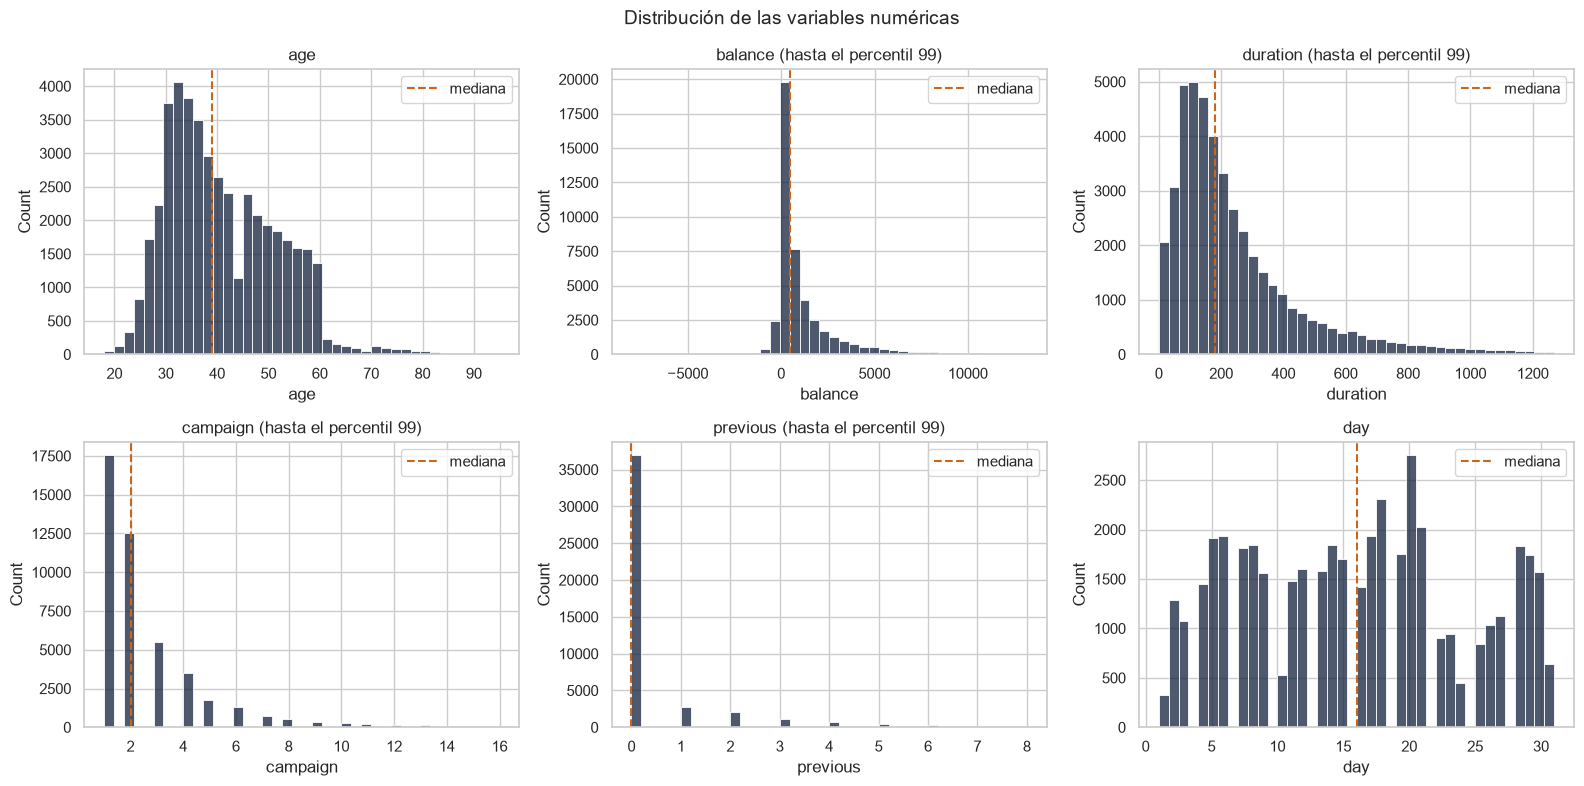

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
variables = ["age", "balance", "duration", "campaign", "previous", "day"]
for ax, col in zip(axes.flat, variables):
    datos = df[col]
    titulo = col
    # Para las variables muy asimétricas mostramos hasta el percentil 99 para que se vea la forma
    if col in ["balance", "duration", "campaign", "previous"]:
        datos = datos[datos <= datos.quantile(0.99)]
        titulo += " (hasta el percentil 99)"
    sns.histplot(datos, bins=40, ax=ax, color="#14213D")
    ax.axvline(df[col].median(), color=COLOR_SI, ls="--", label="mediana")
    ax.set_title(titulo)
    ax.legend()
plt.suptitle("Distribución de las variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

**Lo que vemos:** la edad presenta una concentración alrededor de los 30–50 años, mientras que `balance` y `duration` tienen colas largas. La mayor parte de los clientes tuvo pocos contactos y `previous` vale 0 en la mayoría de los casos. Como las escalas de las variables son distintas, las estandarizaremos para los algoritmos sensibles a distancias o coeficientes.

### 3.3 Boxplots

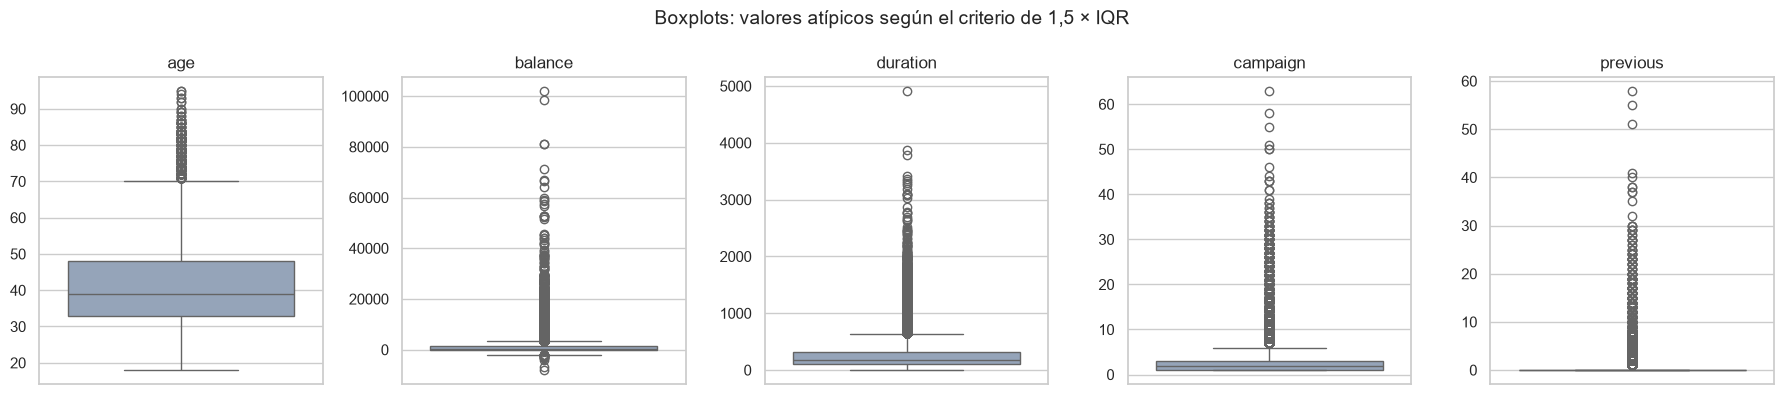

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, ["age", "balance", "duration", "campaign", "previous"]):
    sns.boxplot(y=df[col], ax=ax, color=COLOR_NO)
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Boxplots: valores atípicos según el criterio de 1,5 × IQR", fontsize=14)
plt.tight_layout()
plt.show()

In [16]:
# Cuántos valores atípicos hay según la regla de 1,5 * IQR
# Regla IQR: llamamos atípicos a puntos fuera de Q1−1,5·IQR y Q3+1,5·IQR.
def contar_atipicos(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

atip = df[["age", "balance", "duration", "campaign", "previous"]].apply(contar_atipicos).to_frame("atipicos")
atip["porcentaje"] = (atip["atipicos"] / len(df) * 100).round(1)
atip

,atipicos,porcentaje
age,487,1.1
balance,4729,10.5
duration,3235,7.2
campaign,3064,6.8
previous,8256,18.3


Los boxplots muestran valores alejados del grupo principal en `balance`, `duration` y `campaign`. No los eliminamos: que un valor sea atípico no significa que esté mal. En `previous`, el predominio de ceros hace que la regla de 1,5 veces el rango intercuartílico marque muchos registros como atípicos; ese criterio no es adecuado para decidir qué filas borrar.

### 3.4 Variables categóricas

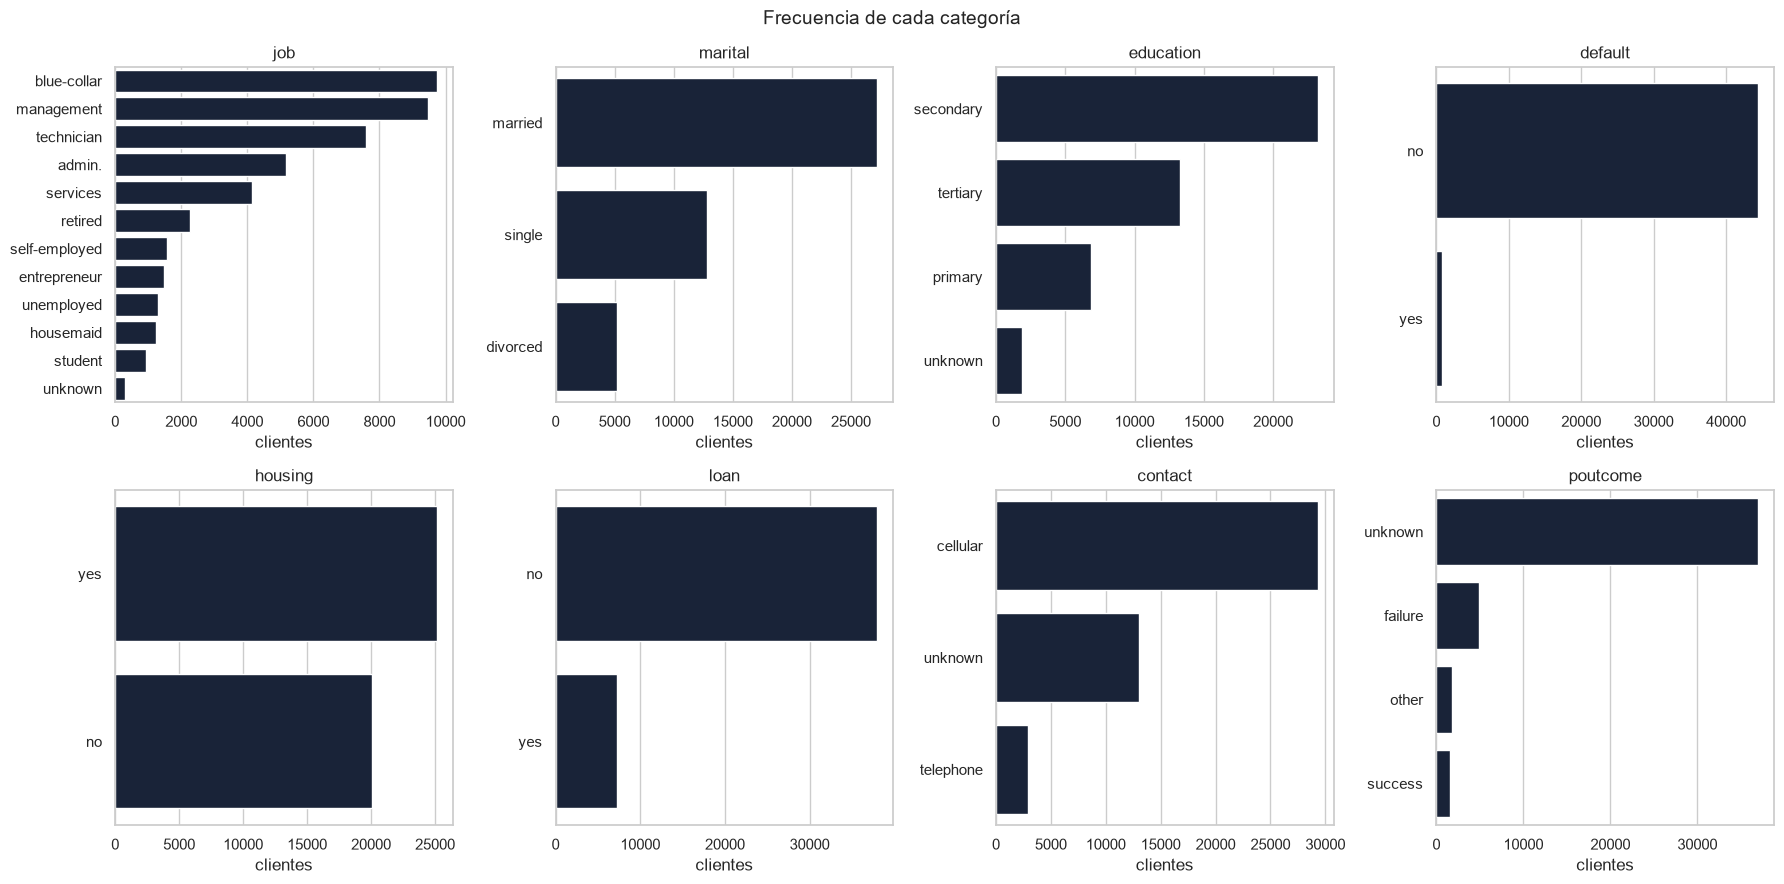

In [17]:
cats = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.flat, cats):
    conteo = df[col].value_counts()
    sns.barplot(x=conteo.values, y=conteo.index, ax=ax, color="#14213D")
    ax.set_title(col)
    ax.set_xlabel("clientes")
    ax.set_ylabel("")
plt.suptitle("Frecuencia de cada categoría", fontsize=14)
plt.tight_layout()
plt.show()

**Lectura:** predominan los trabajos *blue-collar*, *management* y *technician*, los casados y la educación secundaria. Casi nadie tiene créditos en mora (`default`), el 56% tiene hipoteca y la mayoría fue contactada por celular. En `poutcome`, `"unknown"` (no hubo campaña anterior) es abrumadora mayoría.

### 3.5 La variable objetivo

y
no     88.3 %
yes    11.7 %
Name: proportion, dtype: str


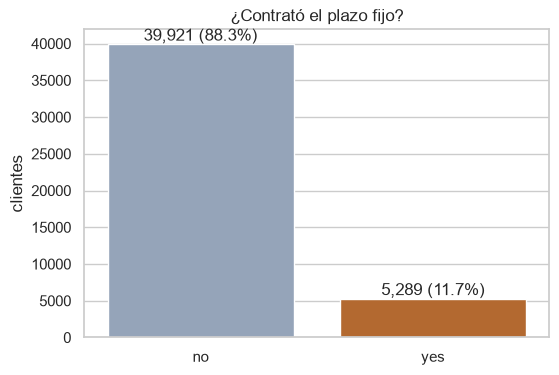

In [18]:
dist_y = df["y"].value_counts()
print((df["y"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=dist_y.index, y=dist_y.values, hue=dist_y.index, palette=PALETA_Y, ax=ax, legend=False)
for i, v in enumerate(dist_y.values):
    ax.text(i, v, f"{v:,} ({v / len(df):.1%})", ha="center", va="bottom")
ax.set_title("¿Contrató el plazo fijo?")
ax.set_xlabel("")
ax.set_ylabel("clientes")
plt.show()

**El problema está desbalanceado:** aproximadamente 11,7% de los clientes contrató. Si siempre dijéramos «no», acertaríamos cerca de 88,3% de los registros, pero no detectaríamos ninguna contratación. Por eso, además de accuracy, vamos a mirar recall, precision, F1 y métricas de ordenamiento como PR-AUC.

## 4. EDA bivariado
### 4.1 Correlación entre variables numéricas (mapa de calor)
Incluimos `y_num` (1 = contrató) para ver qué variable numérica se asocia más con el objetivo.

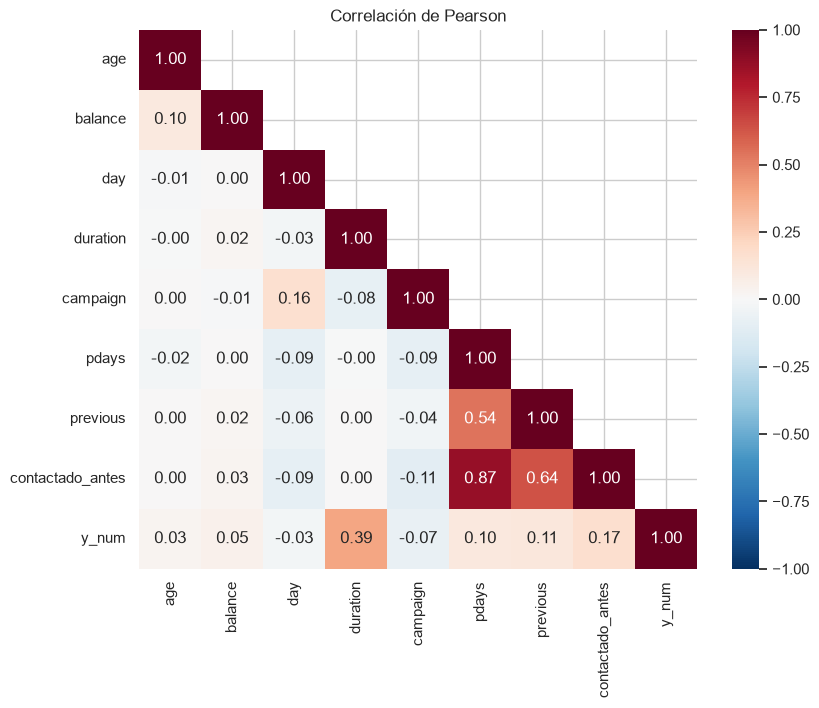

duration            0.39
contactado_antes    0.17
previous            0.11
pdays               0.10
balance             0.05
age                 0.03
day                -0.03
campaign           -0.07
Name: y_num, dtype: float64

In [19]:
corr = df[num_cols + ["contactado_antes", "y_num"]].corr()

fig, ax = plt.subplots(figsize=(9, 7))
# La matriz de correlación es simétrica: ocultamos el triángulo repetido.
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Pearson")
plt.show()

corr["y_num"].drop("y_num").sort_values(ascending=False).round(2)

**Lo que encontramos:**

- `duration` tiene una de las asociaciones numéricas más fuertes con la contratación. No podemos usarla para decidir antes de llamar porque sería fuga de información.
- El resto de las correlaciones lineales con `y_num` es relativamente bajo. Esto no significa que las variables no sirvan: las relaciones podrían ser no lineales o depender de varias características combinadas.
- `pdays`, `previous` y `contactado_antes` están relacionadas porque describen parte del historial de contactos.
- Las variables categóricas todavía no están representadas en esta matriz. Las analizamos en el apartado 4.4.

Una correlación no demuestra que una variable *cause* mayor o menor contratación.

### 4.2 Scatterplots

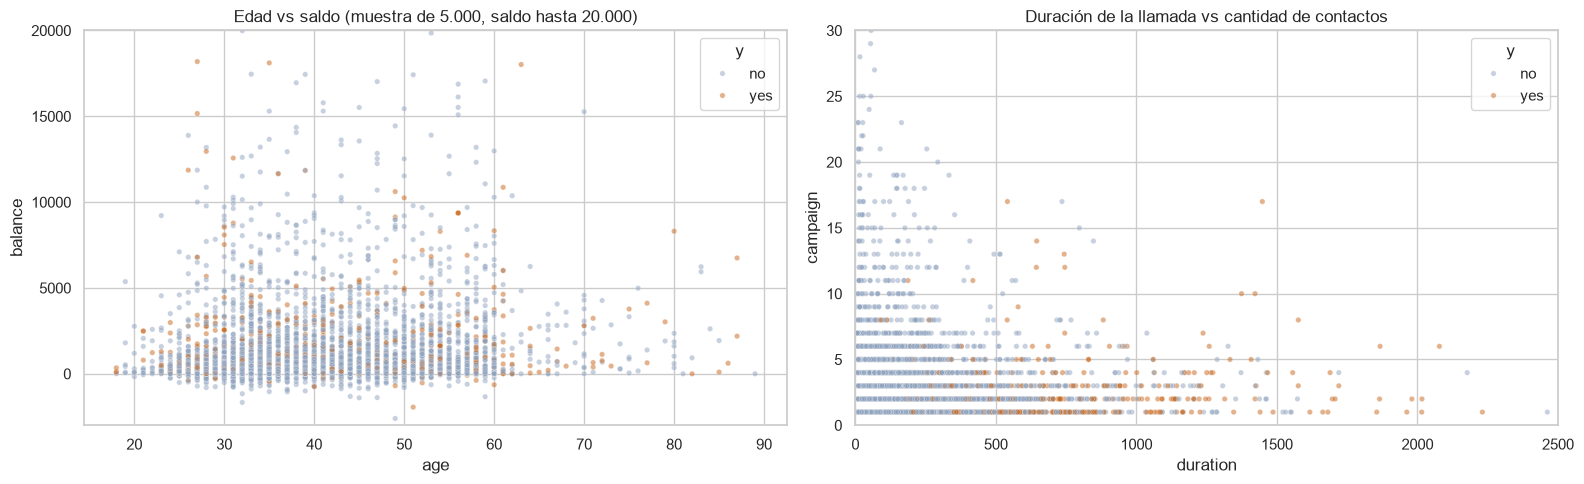

In [20]:
muestra = df.sample(min(5000, len(df)), random_state=SEMILLA)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=muestra, x="age", y="balance", hue="y", palette=PALETA_Y,
                hue_order=["no", "yes"], alpha=0.5, s=15, ax=axes[0])
axes[0].set_ylim(-3000, 20000)
axes[0].set_title("Edad vs saldo (muestra de 5.000, saldo hasta 20.000)")

sns.scatterplot(data=muestra, x="duration", y="campaign", hue="y", palette=PALETA_Y,
                hue_order=["no", "yes"], alpha=0.5, s=15, ax=axes[1])
axes[1].set_xlim(0, 2500)
axes[1].set_ylim(0, 30)
axes[1].set_title("Duración de la llamada vs cantidad de contactos")
plt.tight_layout()
plt.show()

En el gráfico de edad y saldo, clientes que contrataron y que no contrataron aparecen mezclados. No surge una separación clara usando solo estas dos características. En el gráfico de duración de llamada se observa una asociación más marcada, pero esa variable no sería válida para la predicción previa al contacto.

### 4.3 Variables numéricas según la variable objetivo

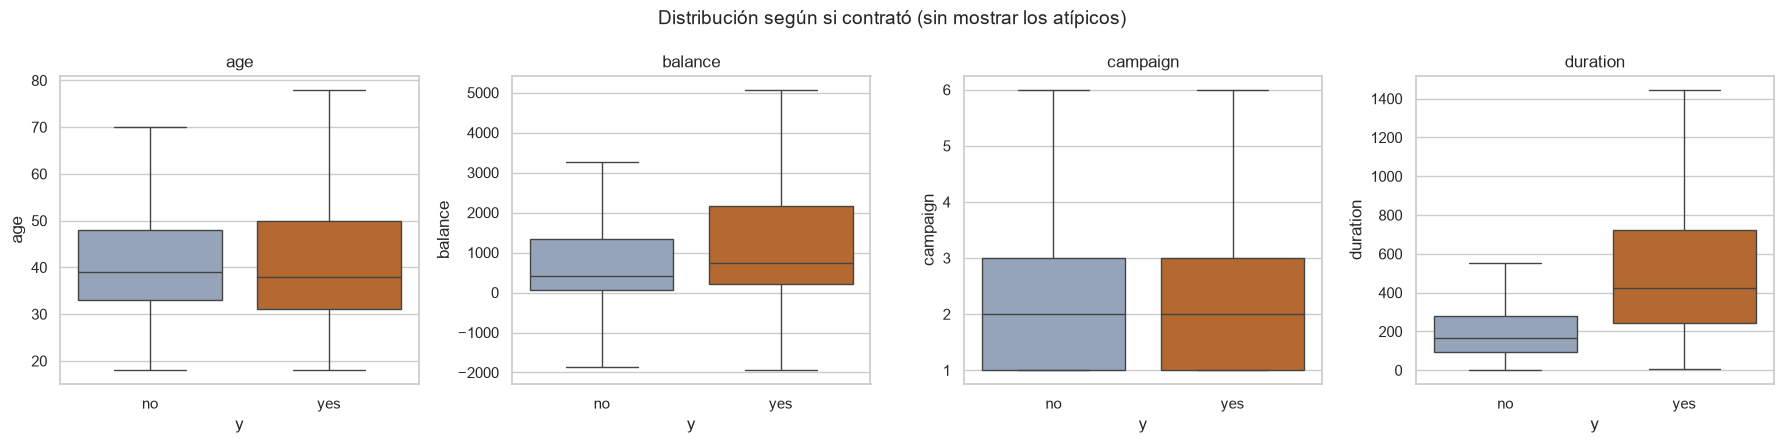

,age,balance,campaign,duration
y,,,,
no,39.0,417.0,2.0,164.0
yes,38.0,733.0,2.0,426.0


In [21]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, ["age", "balance", "campaign", "duration"]):
    sns.boxplot(data=df, x="y", y=col, hue="y", palette=PALETA_Y, order=["no", "yes"],
                showfliers=False, ax=ax, legend=False)
    ax.set_title(col)
plt.suptitle("Distribución según si contrató (sin mostrar los atípicos)", fontsize=14)
plt.tight_layout()
plt.show()

df.groupby("y")[["age", "balance", "campaign", "duration"]].median()

**Lectura:**
- **`duration`:** la diferencia es enorme (mediana de 164 s contra 426 s). De nuevo, es fuga de información.
- **`balance`:** los que contratan tienen un saldo mediano algo mayor (≈ 730 € contra ≈ 420 €).
- **`campaign`:** los que contratan necesitaron menos contactos. Se observa una asociación, no necesariamente un efecto causal de insistir.
- **`age`:** las medianas son parecidas, pero el rango de los `yes` es más amplio (más jóvenes y más mayores).

### 4.4 Variables categóricas y tasa de contratación

Como `y_num` vale 1 cuando hubo contratación, el promedio de esa columna dentro de un grupo representa su **tasa de contratación**. La calculamos junto con la cantidad de registros usando `groupby().agg()`. Revisar el tamaño de cada grupo es importante: un porcentaje alto obtenido con pocos casos puede ser engañoso.

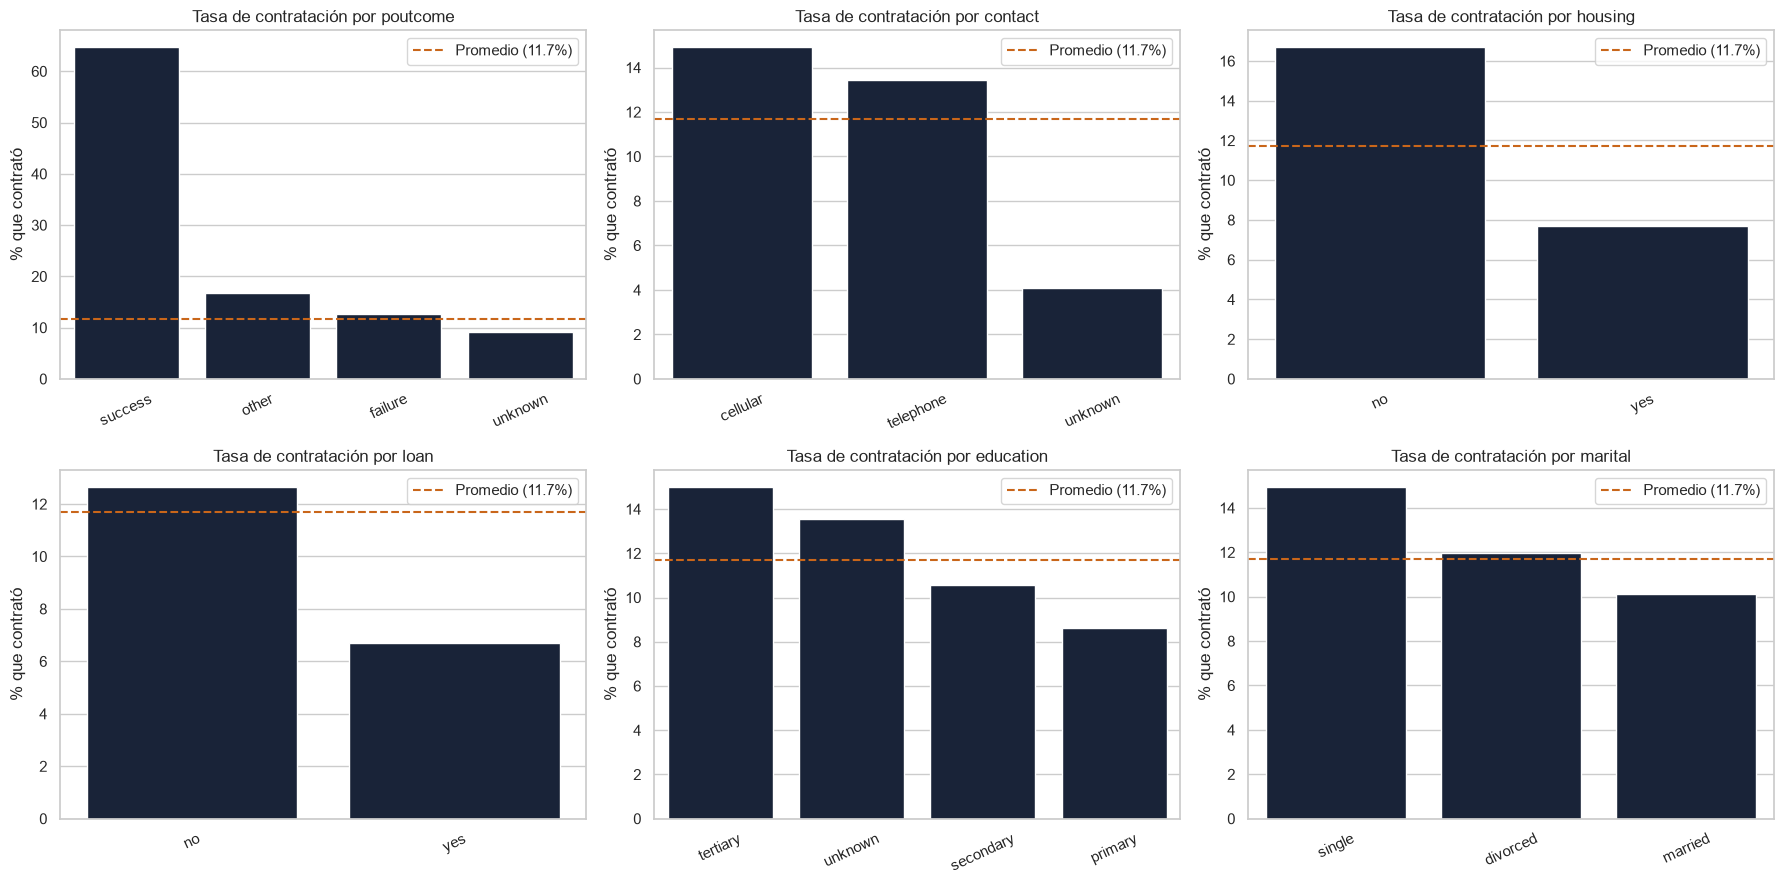

,clientes,tasa_conversion
poutcome,,
success,1511,64.7%
other,1839,16.7%
failure,4901,12.6%
unknown,36959,9.2%


In [22]:
# Tasas de contratación según distintas características del cliente.
# Evitamos .style.format(): puede fallar según las versiones de Pandas/IPython.
TASA_GLOBAL = df["y_num"].mean()

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, ["poutcome", "contact", "housing", "loan", "education", "marital"]):
    resumen_grupo = (
        df.groupby(col, observed=True)
          .agg(tasa_conversion=("y_num", "mean"), clientes=("y_num", "size"))
          .sort_values("tasa_conversion", ascending=False)
    )
    sns.barplot(x=resumen_grupo.index.astype(str),
                y=resumen_grupo["tasa_conversion"] * 100,
                ax=ax, color="#14213D")
    ax.axhline(TASA_GLOBAL * 100, color=COLOR_SI, ls="--",
               label=f"Promedio ({TASA_GLOBAL:.1%})")
    ax.set_title(f"Tasa de contratación por {col}")
    ax.set_ylabel("% que contrató")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    ax.legend()
plt.tight_layout()
plt.show()

resumen_poutcome = (df.groupby("poutcome", observed=True)
                     .agg(clientes=("y_num", "size"), tasa_conversion=("y_num", "mean"))
                     .sort_values("tasa_conversion", ascending=False))
resumen_visible = resumen_poutcome.copy()
resumen_visible["tasa_conversion"] = resumen_visible["tasa_conversion"].map(lambda p: f"{p:.1%}")
display(resumen_visible)

**Lectura:**

- `poutcome` destaca: quienes tuvieron `success` en la campaña anterior presentan una tasa de contratación muy superior al promedio. Aun así, se trata de una asociación y no asegura que vuelvan a contratar.
- En `contact`, la categoría `unknown` tiene una tasa menor. El dato puede reflejar condiciones de la campaña o de su registro, no necesariamente diferencias propias de los clientes.
- En los grupos sin `housing` o sin `loan` se observa una proporción mayor de contrataciones. No podemos afirmar que la ausencia de préstamos sea la causa.
- En educación y estado civil también hay diferencias, pero son más moderadas. Hay que considerarlas junto con el tamaño de cada grupo.

En el modelo vamos a conservar `poutcome` como antecedente histórico, pero excluiremos `contact` de la llamada actual.

---
# 5. Preparación para los modelos

Usamos los mismos datos de entrenamiento y prueba en todos los algoritmos. El **75%** queda para entrenamiento y el **25%** para una evaluación final que no se utiliza para seleccionar hiperparámetros.

**Variables incluidas:** edad, saldo, cantidad de contactos anteriores, indicador de contacto anterior, trabajo, estado civil, educación, mora, hipoteca, préstamo personal y resultado de la campaña anterior.

**Variables excluidas:** `duration` (se conoce después), `day`, `month`, `contact` y `campaign` (describen condiciones del contacto actual) y `pdays` (decisión de preprocesamiento explicada antes). Esto evita comparar modelos con información que no tendríamos al momento de seleccionar al cliente.

Los `Pipeline` hacen que las medianas, las escalas y la codificación de categorías se aprendan exclusivamente con las observaciones usadas para entrenar cada modelo. Así evitamos filtraciones desde el test o desde los pliegues de validación.

In [23]:
variables_numericas = ["age", "balance", "previous", "contactado_antes"]
variables_categoricas = ["job", "marital", "education", "default", "housing", "loan", "poutcome"]
variables_modelo = variables_numericas + variables_categoricas

X = df[variables_modelo].copy()
y = df["y_num"].copy()
# stratify conserva aproximadamente la proporción de sí/no en ambos grupos.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEMILLA, stratify=y
)
assert set(X_train.index).isdisjoint(X_test.index)
print(f"Train: {len(X_train):,} registros ({y_train.mean():.1%} sí)")
print(f"Test:  {len(X_test):,} registros ({y_test.mean():.1%} sí)")

# Evitar posibles diferencias entre versiones de scikit-learn.
try:
    codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # scikit-learn < 1.2
    codificador = OneHotEncoder(handle_unknown="ignore", sparse=False)

# ColumnTransformer aplica pasos distintos a columnas numéricas y categóricas.
# StandardScaler centra y escala; OneHotEncoder crea columnas 0/1 para categorías.
preprocesamiento = ColumnTransformer(transformers=[
    ("numericas", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), variables_numericas),
    ("categoricas", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", codificador)
    ]), variables_categoricas)
])

# Pipeline ejecuta transformación + modelo juntos; evita aprender estadísticas del test.
def crear_pipeline(clasificador):
    return Pipeline([
        ("preprocesamiento", clone(preprocesamiento)),
        ("clasificador", clasificador)
    ])

# Calculamos métricas de clasificación y de ranking (ROC-AUC y PR-AUC).
def evaluar(y_real, pred, puntaje):
    return {
        "Accuracy": accuracy_score(y_real, pred),
        "Precision (yes)": precision_score(y_real, pred, zero_division=0),
        "Recall (yes)": recall_score(y_real, pred, zero_division=0),
        "F1 (yes)": f1_score(y_real, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_real, puntaje),
        "PR-AUC (AP)": average_precision_score(y_real, puntaje),
    }

# Reducimos el costo del experimento inicial sin cambiar mucho la tasa de sí/no.
def muestra_estratificada(X_original, y_original, max_filas, semilla):
    if len(y_original) <= max_filas:
        return X_original.copy(), y_original.copy()
    X_m, _, y_m, _ = train_test_split(
        X_original, y_original, train_size=max_filas,
        random_state=semilla, stratify=y_original
    )
    return X_m, y_m

Train: 33,907 registros (11.7% sí)
Test:  11,303 registros (11.7% sí)


# 6. Comparación inicial de algoritmos

Antes de elegir los modelos principales, comparamos cuatro alternativas y un baseline en una **validación interna del entrenamiento**, sin usar el test final. Para agilizar KNN usamos la **misma muestra estratificada** de 12.000 clientes para entrenar y 3.000 para validar.

- **Regresión Lineal:** referencia didáctica; aplicamos umbral 0,5, aunque su salida no es una probabilidad.
- **KNN (k=25):** clasifica por cercanía entre clientes; requiere escalado y puede ser más lento al predecir.
- **Regresión Logística:** clasificación binaria interpretable.
- **Random Forest:** combina árboles y capta relaciones no lineales.

**Criterio:** además de accuracy comparamos **PR-AUC**, más informativa para priorizar clientes que contratan (clase minoritaria). Profundizamos en Logística y Random Forest por su utilidad e interpretabilidad, sin ocultar el desempeño de las otras alternativas.

In [24]:
X_exploracion, X_validacion, y_exploracion, y_validacion = train_test_split(
    X_train, y_train, test_size=0.25, random_state=SEMILLA, stratify=y_train
)
X_exploracion, y_exploracion = muestra_estratificada(
    X_exploracion, y_exploracion, 12000, SEMILLA
)
X_validacion, y_validacion = muestra_estratificada(
    X_validacion, y_validacion, 3000, SEMILLA + 1
)

modelos_iniciales = {
    "Siempre no": DummyClassifier(strategy="most_frequent"),
    "Regresión lineal (umbral 0,5)": crear_pipeline(LinearRegression()),
    "KNN (k=25)": crear_pipeline(KNeighborsClassifier(n_neighbors=25)),
    "Regresión logística inicial": crear_pipeline(LogisticRegression(max_iter=2000, C=1.0)),
    "Random Forest inicial": crear_pipeline(RandomForestClassifier(
        n_estimators=100, max_depth=12, min_samples_leaf=5,
        random_state=SEMILLA, n_jobs=1
    ))
}

resultados_iniciales = []
# Todos los algoritmos reciben las mismas filas; la salida de lineal usa un umbral.
for nombre, modelo in modelos_iniciales.items():
    modelo.fit(X_exploracion, y_exploracion)
    if nombre.startswith("Regresión lineal"):
        puntaje = modelo.predict(X_validacion)  # Predicción continua (no probabilidad)
        pred = (puntaje >= 0.5).astype(int)
    else:
        puntaje = modelo.predict_proba(X_validacion)[:, list(modelo.classes_).index(1)]
        pred = modelo.predict(X_validacion)
    resultados_iniciales.append({"Modelo": nombre, **evaluar(y_validacion, pred, puntaje)})

tabla_inicial = (pd.DataFrame(resultados_iniciales)
                 .set_index("Modelo").sort_values("PR-AUC (AP)", ascending=False))
print("Comparación EXPLORATORIA (solo validación dentro de train):")
display(tabla_inicial.round(3))

Comparación EXPLORATORIA (solo validación dentro de train):


,Accuracy,Precision (yes),Recall (yes),F1 (yes),ROC-AUC,PR-AUC (AP)
Modelo,,,,,,
Random Forest inicial,0.896,0.753,0.165,0.271,0.746,0.391
Regresión logística inicial,0.896,0.750,0.171,0.278,0.740,0.377
"Regresión lineal (umbral 0,5)",0.896,0.689,0.202,0.313,0.739,0.368
KNN (k=25),0.892,0.691,0.134,0.224,0.707,0.329
Siempre no,0.883,0.000,0.000,0.000,0.500,0.117


**Lectura de la comparación inicial:**
- Los cuatro modelos superan al baseline en PR-AUC, pero ninguno por mucho: con la información disponible antes de llamar, el problema es difícil.
- **KNN** queda último en PR-AUC y ROC-AUC. Con muchas columnas 0/1 las distancias discriminan poco, y es el más lento para predecir.
- **La Regresión Lineal** tiene el F1 más alto, pero eso depende del umbral fijo de 0,5 aplicado a una salida que no es una probabilidad. **La PR-AUC compara qué tan bien ordena cada modelo sin depender del umbral**, y por eso es nuestro criterio principal.
- **Random Forest y Regresión Logística** quedan arriba en PR-AUC: son los dos modelos que analizamos en profundidad.

---
# 7. Regresión Logística

Estima la probabilidad de contratar a partir de las características del cliente. Es rápida e interpretable, pero modela principalmente relaciones lineales en el logaritmo de las probabilidades relativas (*log-odds*).

### 7.1 Búsqueda de hiperparámetros con validación cruzada

Probamos **6 combinaciones** mediante validación cruzada estratificada de **3 pliegues**, eligiendo la mayor **PR-AUC promedio**: `C = 0.05, 0.5, 5` (menor C = mayor regularización), combinado con `class_weight = None` o `balanced` (ponderación de la clase minoritaria). El test queda reservado.

In [25]:
validacion_cruzada = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)

logistica = crear_pipeline(LogisticRegression(
    solver="lbfgs", max_iter=2000, random_state=SEMILLA
))
parametros_lr = {
    "clasificador__C": [0.05, 0.5, 5.0],
    "clasificador__class_weight": [None, "balanced"]
}

# GridSearchCV prueba TODAS las combinaciones y promedia el resultado en 3 pliegues.
# scoring=average_precision prioriza detectar y ordenar la clase minoritaria.
busqueda_lr = GridSearchCV(
    logistica, parametros_lr, scoring="average_precision",
    cv=validacion_cruzada, n_jobs=1, refit=True,
    return_train_score=True, error_score="raise"
)
busqueda_lr.fit(X_train, y_train)
modelo_lr = busqueda_lr.best_estimator_

resultados_cv_lr = pd.DataFrame(busqueda_lr.cv_results_)
columnas_lr = ["param_clasificador__C", "param_clasificador__class_weight",
               "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]
tabla_cv_lr = resultados_cv_lr[columnas_lr].sort_values("rank_test_score").rename(columns={
    "param_clasificador__C": "C", "param_clasificador__class_weight": "Peso de clases",
    "mean_test_score": "PR-AUC CV", "std_test_score": "Desvío CV",
    "mean_train_score": "PR-AUC train", "rank_test_score": "Puesto"
})
print("Combinaciones probadas (ordenadas por PR-AUC media en CV):")
display(tabla_cv_lr.round(3))
print("Mejores hiperparámetros de Logística:", busqueda_lr.best_params_)
print(f"PR-AUC promedio de validación cruzada: {busqueda_lr.best_score_:.3f}")

Combinaciones probadas (ordenadas por PR-AUC media en CV):


,C,Peso de clases,PR-AUC CV,Desvío CV,PR-AUC train,Puesto
0,0.05,NaN,0.343,0.013,0.346,1
2,0.50,NaN,0.343,0.013,0.346,2
4,5.00,NaN,0.343,0.013,0.346,3
3,0.50,balanced,0.341,0.013,0.344,4
5,5.00,balanced,0.341,0.013,0.344,5
1,0.05,balanced,0.341,0.013,0.344,6


Mejores hiperparámetros de Logística: {'clasificador__C': 0.05, 'clasificador__class_weight': None}
PR-AUC promedio de validación cruzada: 0.343


### 7.2 Qué variables pesan en la decisión

Los coeficientes positivos aumentan los *log-odds* estimados de contratación y los negativos los reducen, manteniendo constantes las demás columnas. Los valores numéricos fueron estandarizados. Como las variables categóricas se codifican con *one-hot*, **no debemos interpretar cada coeficiente como si fuera un efecto causal**.

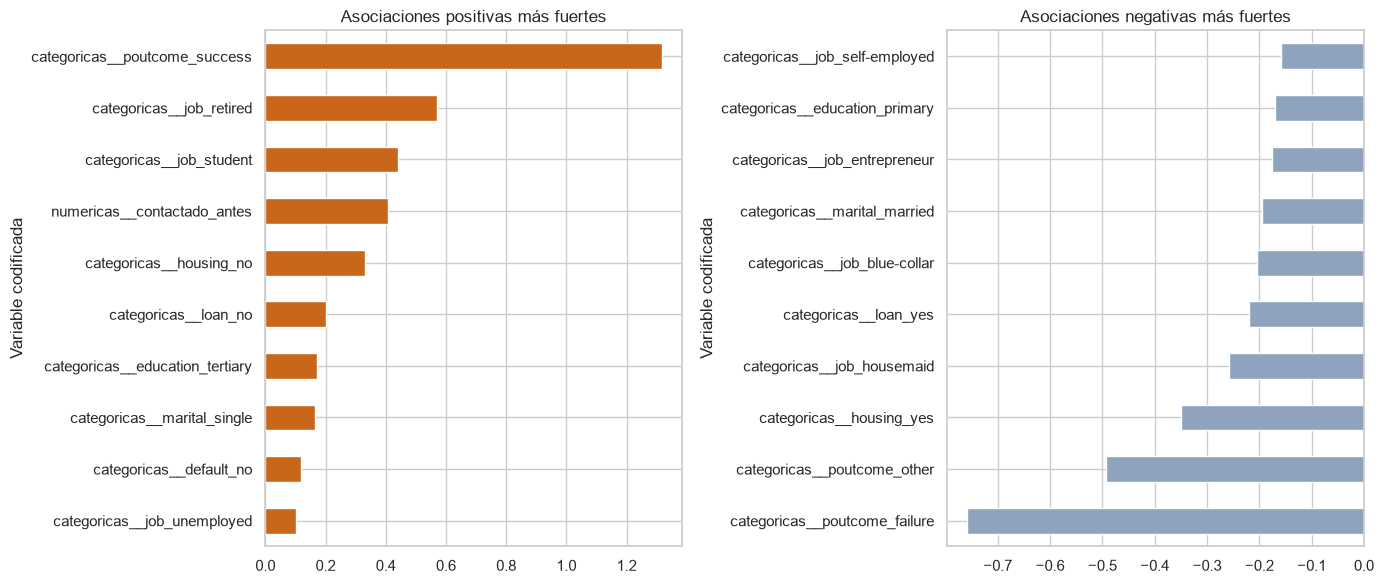

In [26]:
# get_feature_names_out recupera las columnas creadas tras el one-hot encoding.
nombres_features_lr = modelo_lr.named_steps["preprocesamiento"].get_feature_names_out()
coef_lr = pd.DataFrame({
    "Variable codificada": nombres_features_lr,
    "Coeficiente": modelo_lr.named_steps["clasificador"].coef_.ravel()
})
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
coef_lr.nlargest(10, "Coeficiente").sort_values("Coeficiente").plot.barh(
    x="Variable codificada", y="Coeficiente", ax=axes[0], legend=False, color="#C9661A"
)
axes[0].set_title("Asociaciones positivas más fuertes")
coef_lr.nsmallest(10, "Coeficiente").sort_values("Coeficiente").plot.barh(
    x="Variable codificada", y="Coeficiente", ax=axes[1], legend=False, color="#8FA3BF"
)
axes[1].set_title("Asociaciones negativas más fuertes")
plt.tight_layout()
plt.show()

---
# 8. Random Forest

Combina muchos árboles de decisión y puede detectar relaciones no lineales e interacciones entre variables. A cambio, cuesta más interpretar cada predicción.

### 8.1 Búsqueda de hiperparámetros con validación cruzada

Probamos **12 configuraciones aleatorias reproducibles** de un total de 24, con los mismos **3 pliegues y PR-AUC** usados en Logística. Los parámetros estudiados fueron `n_estimators` (80/150 árboles), `max_depth` (8/14/sin límite), `min_samples_leaf` (3/10 observaciones) y `class_weight` (sin pesos/balanced_subsample).

**Cómo elegimos (regla de un desvío):** las mejores configuraciones quedan prácticamente empatadas (diferencias de milésimas, menores que el desvío entre pliegues). Elegir "la de mayor PR-AUC" en ese caso es elegir por azar, y de hecho el ganador puede cambiar al ejecutar en otra computadora. Por eso tomamos todas las configuraciones que quedan **a menos de un desvío estándar de la mejor** y, entre ellas, elegimos **la más simple**: menor profundidad, menos árboles, hojas más grandes y sin pesos de clase. Un modelo más simple con el mismo rendimiento generaliza igual de bien y es más estable.

In [27]:
bosque = crear_pipeline(RandomForestClassifier(random_state=SEMILLA, n_jobs=1))
parametros_rf = {
    "clasificador__n_estimators": [80, 150],
    "clasificador__max_depth": [8, 14, None],
    "clasificador__min_samples_leaf": [3, 10],
    "clasificador__class_weight": [None, "balanced_subsample"]
}

# RandomizedSearchCV toma 12 combinaciones de forma reproducible (random_state).
busqueda_rf = RandomizedSearchCV(
    bosque, parametros_rf, n_iter=12, scoring="average_precision",
    cv=validacion_cruzada, n_jobs=1, random_state=SEMILLA,
    refit=False, return_train_score=True, error_score="raise"
)
busqueda_rf.fit(X_train, y_train)
resultados_cv_rf = pd.DataFrame(busqueda_rf.cv_results_)

# Regla de un desvío: candidatas a menos de 1 desvío estándar de la mejor PR-AUC media.
i_mejor = resultados_cv_rf["mean_test_score"].idxmax()
limite = resultados_cv_rf.loc[i_mejor, "mean_test_score"] - resultados_cv_rf.loc[i_mejor, "std_test_score"]
resultados_cv_rf["Candidata"] = resultados_cv_rf["mean_test_score"] >= limite

# Entre las candidatas, la más simple: menor profundidad, menos árboles, hojas más grandes, sin pesos.
es_nulo = lambda v: v is None or (isinstance(v, float) and np.isnan(v))
simplicidad = pd.DataFrame({
    "profundidad": resultados_cv_rf["param_clasificador__max_depth"].map(lambda v: np.inf if es_nulo(v) else v),
    "arboles": resultados_cv_rf["param_clasificador__n_estimators"],
    "hoja": resultados_cv_rf["param_clasificador__min_samples_leaf"],
    "con_pesos": resultados_cv_rf["param_clasificador__class_weight"].map(lambda v: 0 if es_nulo(v) else 1),
})[resultados_cv_rf["Candidata"]]
indice_rf = simplicidad.sort_values(["profundidad", "arboles", "hoja", "con_pesos"],
                                    ascending=[True, True, False, True]).index[0]
params_rf = resultados_cv_rf.loc[indice_rf, "params"]
score_rf = resultados_cv_rf.loc[indice_rf, "mean_test_score"]

# Reentrenamos la configuración elegida con todo el conjunto de entrenamiento.
modelo_rf = clone(bosque).set_params(**params_rf).fit(X_train, y_train)

texto_param = lambda v, nulo: nulo if es_nulo(v) else v
tabla_cv_rf = pd.DataFrame({
    "Árboles": resultados_cv_rf["param_clasificador__n_estimators"],
    "Profundidad máxima": resultados_cv_rf["param_clasificador__max_depth"].map(lambda v: texto_param(v, "sin límite")),
    "Mín. por hoja": resultados_cv_rf["param_clasificador__min_samples_leaf"],
    "Peso de clases": resultados_cv_rf["param_clasificador__class_weight"].map(lambda v: texto_param(v, "sin pesos")),
    "PR-AUC CV": resultados_cv_rf["mean_test_score"],
    "Desvío CV": resultados_cv_rf["std_test_score"],
    "PR-AUC train": resultados_cv_rf["mean_train_score"],
    "A menos de 1 desvío": resultados_cv_rf["Candidata"].map({True: "sí", False: "no"}),
}).sort_values("PR-AUC CV", ascending=False)
print("12 combinaciones evaluadas (ordenadas por PR-AUC CV):")
display(tabla_cv_rf.round(3))
print(f"Límite de la regla de un desvío: PR-AUC CV >= {limite:.3f}")
print("Configuración elegida (la más simple entre las candidatas):",
      {k.replace("clasificador__", ""): v for k, v in params_rf.items()})
print(f"PR-AUC promedio de validación cruzada de la elegida: {score_rf:.3f}")

12 combinaciones evaluadas (ordenadas por PR-AUC CV):


,Árboles,Profundidad máxima,Mín. por hoja,Peso de clases,PR-AUC CV,Desvío CV,PR-AUC train,A menos de 1 desvío
3,80,14,10,balanced_subsample,0.366,0.017,0.461,sí
7,150,8,3,sin pesos,0.365,0.018,0.432,sí
2,80,8,3,sin pesos,0.365,0.019,0.430,sí
4,150,sin límite,10,sin pesos,0.364,0.016,0.481,sí
11,80,8,3,balanced_subsample,0.364,0.018,0.426,sí
6,150,8,3,balanced_subsample,0.363,0.018,0.428,sí
10,80,8,10,sin pesos,0.363,0.017,0.411,sí
9,150,14,3,sin pesos,0.362,0.016,0.558,sí
1,80,14,3,balanced_subsample,0.357,0.015,0.552,sí
5,150,sin límite,3,sin pesos,0.349,0.013,0.700,no


Límite de la regla de un desvío: PR-AUC CV >= 0.349
Configuración elegida (la más simple entre las candidatas): {'n_estimators': 80, 'min_samples_leaf': 10, 'max_depth': 8, 'class_weight': None}
PR-AUC promedio de validación cruzada de la elegida: 0.363


### 8.2 Importancia de las variables

El bosque informa cuánta reducción de impureza se atribuye a cada columna usada en las divisiones. **Es una medida interna del modelo, no una relación causal**; además, puede favorecer variables que ofrecen muchos posibles cortes. La usamos como orientación, no como prueba de que una característica determine la contratación.

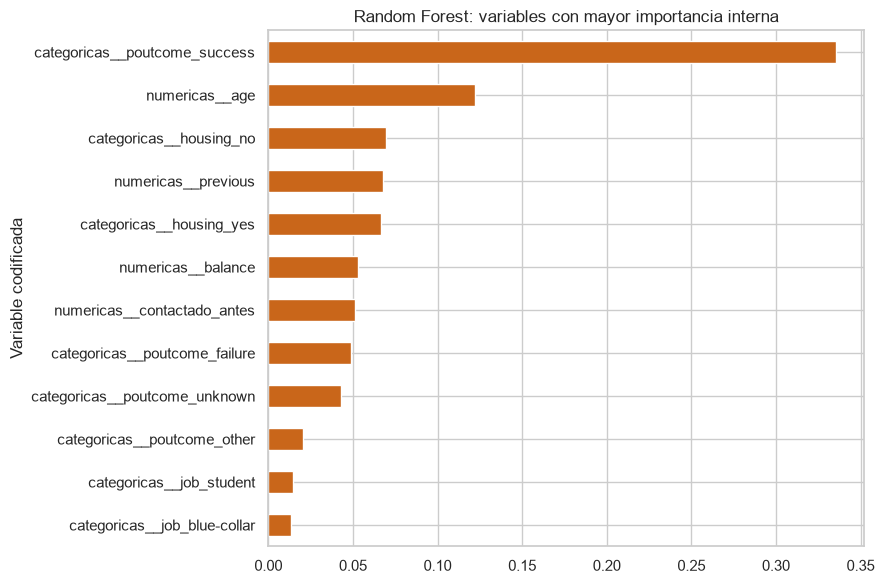

In [28]:
# feature_importances_ mide la reducción de impureza aportada por cada variable.
nombres_features_rf = modelo_rf.named_steps["preprocesamiento"].get_feature_names_out()
importancia_rf = (pd.DataFrame({
    "Variable codificada": nombres_features_rf,
    "Importancia": modelo_rf.named_steps["clasificador"].feature_importances_
}).sort_values("Importancia", ascending=False))

fig, ax = plt.subplots(figsize=(9, 6))
importancia_rf.head(12).iloc[::-1].plot.barh(
    x="Variable codificada", y="Importancia", ax=ax, legend=False, color="#C9661A"
)
ax.set_title("Random Forest: variables con mayor importancia interna")
plt.tight_layout()
plt.show()

---
# 9. Comparación final de ambos modelos

Recién ahora evaluamos el **test reservado**, con las mismas observaciones para ambos modelos y para el baseline «siempre no». Mostramos accuracy, precision, recall, F1, ROC-AUC y **PR-AUC (criterio principal)**. Un umbral de 0,5 sirve para estudiar errores, pero ordenar por probabilidad estimada suele ser más útil para decidir a quién llamar.

In [29]:
modelos_finales = {
    "Baseline (siempre no)": DummyClassifier(strategy="most_frequent").fit(X_train, y_train),
    "Regresión Logística": modelo_lr,
    "Random Forest": modelo_rf,
}

predicciones_finales = {}
filas_metricas = []
# predict da clase 0/1; predict_proba da puntuación para ordenar clientes.
for nombre, modelo in modelos_finales.items():
    pred = modelo.predict(X_test)
    proba = modelo.predict_proba(X_test)[:, list(modelo.classes_).index(1)]
    predicciones_finales[nombre] = {"pred": pred, "proba": proba}
    filas_metricas.append({"Modelo": nombre, **evaluar(y_test, pred, proba)})

tabla_final = pd.DataFrame(filas_metricas).set_index("Modelo")
print("MÉTRICAS FINALES — mismas observaciones de test")
display(tabla_final.round(3))
print("Mejores resultados de validación cruzada (PR-AUC):")
display(pd.DataFrame({
    "Modelo": ["Regresión Logística", "Random Forest"],
    "PR-AUC media CV": [busqueda_lr.best_score_, score_rf],
    "Desvío CV de mejor combinación": [
        resultados_cv_lr.loc[busqueda_lr.best_index_, "std_test_score"],
        resultados_cv_rf.loc[indice_rf, "std_test_score"]
    ]
}).set_index("Modelo").round(3))

MÉTRICAS FINALES — mismas observaciones de test


,Accuracy,Precision (yes),Recall (yes),F1 (yes),ROC-AUC,PR-AUC (AP)
Modelo,,,,,,
Baseline (siempre no),0.883,0.000,0.000,0.000,0.500,0.117
Regresión Logística,0.893,0.683,0.161,0.261,0.725,0.357
Random Forest,0.894,0.714,0.155,0.255,0.739,0.380


Mejores resultados de validación cruzada (PR-AUC):


,PR-AUC media CV,Desvío CV de mejor combinación
Modelo,,
Regresión Logística,0.343,0.013
Random Forest,0.363,0.017


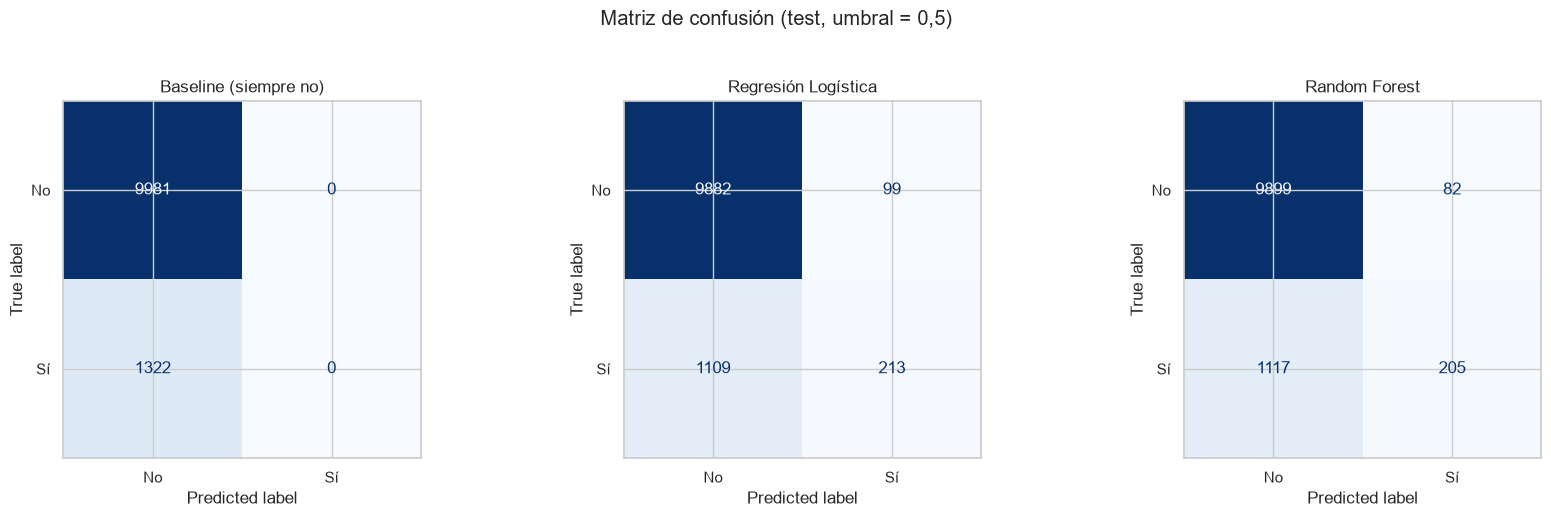

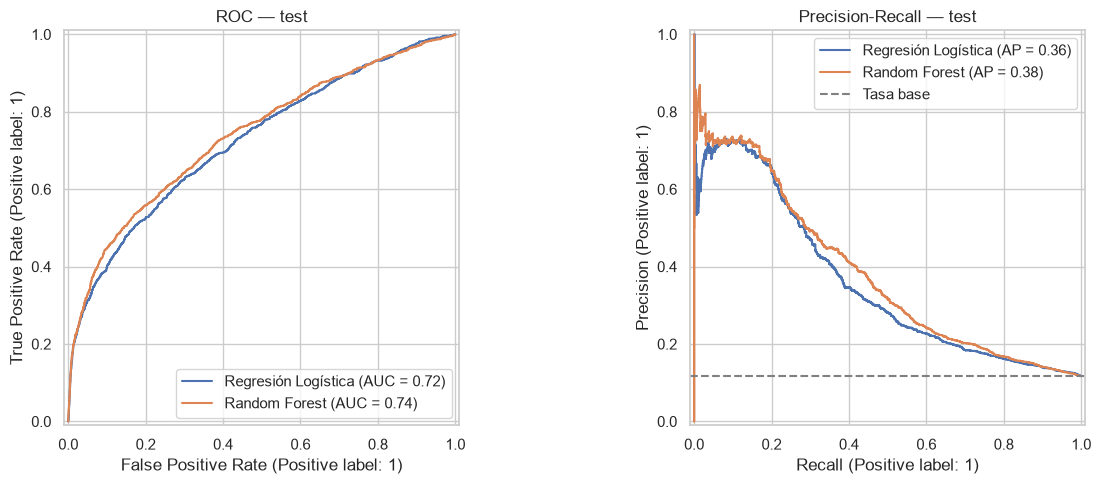

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, nombre in zip(axes, modelos_finales):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicciones_finales[nombre]["pred"],
        labels=[0, 1], display_labels=["No", "Sí"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(nombre)
plt.suptitle("Matriz de confusión (test, umbral = 0,5)", y=1.03)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nombre in ["Regresión Logística", "Random Forest"]:
    RocCurveDisplay.from_predictions(y_test, predicciones_finales[nombre]["proba"],
                                     name=nombre, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, predicciones_finales[nombre]["proba"],
                                             name=nombre, ax=axes[1])
axes[0].set_title("ROC — test")
axes[1].set_title("Precision-Recall — test")
axes[1].axhline(y_test.mean(), color="gray", ls="--", label="Tasa base")
axes[1].legend()
plt.tight_layout()
plt.show()

### 9.1 En qué se equivoca cada modelo

Hay dos errores que tienen significados distintos para el banco. Un **falso positivo (FP)** es alguien que clasificamos como probable contratante pero no contrató. Puede generar un contacto de bajo rendimiento. Un **falso negativo (FN)** es un cliente que sí contrató, pero el modelo habría dejado fuera de su lista de prioridad.

Usando un umbral de 0,5, una baja cantidad de falsos positivos puede venir acompañada de muchos falsos negativos. Por eso presentamos los conteos y también las **tasas**: porcentaje de contratantes no detectados (FN / positivos reales) y porcentaje de no contratantes marcados erróneamente (FP / negativos reales).

In [31]:
filas_errores = []
for nombre, info in predicciones_finales.items():
    # La matriz devuelve verdaderos negativos, falsos positivos, falsos negativos y verdaderos positivos.
    tn, fp, fn, tp = confusion_matrix(y_test, info["pred"], labels=[0, 1]).ravel()
    filas_errores.append({
        "Modelo": nombre, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "% positivos no detectados": fn / (fn + tp),
        "% negativos marcados como sí": fp / (fp + tn),
    })
tabla_errores = pd.DataFrame(filas_errores).set_index("Modelo")
display(tabla_errores.round(3))
for nombre in ["Regresión Logística", "Random Forest"]:
    fila = tabla_errores.loc[nombre]
    print(f"{nombre}: {int(fila['FN']):,} de {int(fila['FN'] + fila['TP']):,} contrataciones "
          f"quedaron sin detectar ({fila['% positivos no detectados']:.1%}). "
          f"Entre los clientes que no contrataron, {fila['% negativos marcados como sí']:.1%} "
          "fueron clasificados como sí.")

,TN,FP,FN,TP,% positivos no detectados,% negativos marcados como sí
Modelo,,,,,,
Baseline (siempre no),9981,0,1322,0,1.000,0.000
Regresión Logística,9882,99,1109,213,0.839,0.010
Random Forest,9899,82,1117,205,0.845,0.008


Regresión Logística: 1,109 de 1,322 contrataciones quedaron sin detectar (83.9%). Entre los clientes que no contrataron, 1.0% fueron clasificados como sí.
Random Forest: 1,117 de 1,322 contrataciones quedaron sin detectar (84.5%). Entre los clientes que no contrataron, 0.8% fueron clasificados como sí.


### Errores según características del cliente

Miramos en qué grupos aparecen más falsos negativos y falsos positivos. **Una cantidad grande de errores no prueba que el modelo funcione peor en ese grupo**, porque también puede haber más clientes. Por eso calculamos tasas *dentro de cada grupo* y mostramos cuántos casos respaldan cada resultado.

Para no sacar conclusiones de grupos diminutos, en la tabla se exige al menos 20 positivos o 20 negativos reales para informar la tasa correspondiente.

In [32]:
# Las tasas se calculan dentro de cada grupo, no sobre el total de la base.
def analizar_errores_por_grupo(nombre_modelo, variable):
    trabajo = pd.DataFrame({
        "grupo": X_test[variable].astype(str).to_numpy(),
        "real": y_test.to_numpy(),
        "pred": predicciones_finales[nombre_modelo]["pred"]
    })
    trabajo["FN"] = ((trabajo["real"] == 1) & (trabajo["pred"] == 0)).astype(int)
    trabajo["FP"] = ((trabajo["real"] == 0) & (trabajo["pred"] == 1)).astype(int)
    resultado = trabajo.groupby("grupo").agg(
        Clientes=("real", "size"), Positivos_reales=("real", "sum"),
        Falsos_negativos=("FN", "sum"), Falsos_positivos=("FP", "sum")
    )
    n_no = resultado["Clientes"] - resultado["Positivos_reales"]
    resultado["% sí omitidos"] = (resultado["Falsos_negativos"] /
                                 resultado["Positivos_reales"].replace(0, np.nan))
    resultado["% no marcados como sí"] = (resultado["Falsos_positivos"] /
                                         n_no.replace(0, np.nan))
    resultado.loc[resultado["Positivos_reales"] < 20, "% sí omitidos"] = np.nan
    resultado.loc[n_no < 20, "% no marcados como sí"] = np.nan
    return resultado.sort_values("Clientes", ascending=False).round(3)

for nombre in ["Regresión Logística", "Random Forest"]:
    print(f"\n{nombre}: errores según resultado de campaña anterior")
    display(analizar_errores_por_grupo(nombre, "poutcome"))
    print(f"{nombre}: errores según crédito hipotecario")
    display(analizar_errores_por_grupo(nombre, "housing"))


Regresión Logística: errores según resultado de campaña anterior


,Clientes,Positivos_reales,Falsos_negativos,Falsos_positivos,% sí omitidos,% no marcados como sí
grupo,,,,,,
unknown,9218,818,818,1,1.000,0.000
failure,1214,165,165,0,1.000,0.000
other,482,81,81,0,1.000,0.000
success,389,258,45,98,0.174,0.748


Regresión Logística: errores según crédito hipotecario


,Clientes,Positivos_reales,Falsos_negativos,Falsos_positivos,% sí omitidos,% no marcados como sí
grupo,,,,,,
yes,6233,471,446,25,0.947,0.004
no,5070,851,663,74,0.779,0.018



Random Forest: errores según resultado de campaña anterior


,Clientes,Positivos_reales,Falsos_negativos,Falsos_positivos,% sí omitidos,% no marcados como sí
grupo,,,,,,
unknown,9218,818,818,0,1.000,0.000
failure,1214,165,165,0,1.000,0.000
other,482,81,81,0,1.000,0.000
success,389,258,53,82,0.205,0.626


Random Forest: errores según crédito hipotecario


,Clientes,Positivos_reales,Falsos_negativos,Falsos_positivos,% sí omitidos,% no marcados como sí
grupo,,,,,,
yes,6233,471,456,7,0.968,0.001
no,5070,851,661,75,0.777,0.018


#### El patrón principal: los modelos dependen de `poutcome = success`

Las tablas anteriores muestran que, con umbral 0,5, **todas** las contrataciones de clientes con `poutcome` igual a `unknown`, `failure` u `other` quedan sin detectar, y los falsos positivos aparecen casi exclusivamente entre los clientes con éxito previo. Es decir: con ese umbral, ambos modelos se comportan casi como la regla «decir sí solo a quien ya contrató en la campaña anterior».

La pregunta es si el **ordenamiento** (que es lo que usamos en 9.2) aporta algo más que esa regla. Lo comprobamos:

In [33]:
es_success = (X_test["poutcome"] == "success").to_numpy()
y_test_arr = y_test.to_numpy()
filas_patron = []
for nombre in ["Regresión Logística", "Random Forest"]:
    pred = predicciones_finales[nombre]["pred"]
    proba = predicciones_finales[nombre]["proba"]
    n10 = int(np.ceil(len(proba) * 0.10))
    top10 = np.argsort(-proba)[:n10]
    sin_exito_top = ~es_success[top10]
    filas_patron.append({
        "Modelo": nombre,
        "Predichos «sí» (umbral 0,5)": int(pred.sum()),
        "% de esos con éxito previo": es_success[pred == 1].mean() if pred.sum() else np.nan,
        "Clientes en el top 10%": n10,
        "Top 10% sin éxito previo": int(sin_exito_top.sum()),
        "Contrataciones del top 10% sin éxito previo": int(y_test_arr[top10][sin_exito_top].sum()),
    })
display(pd.DataFrame(filas_patron).set_index("Modelo").round(3))
print(f"Clientes del test con poutcome = success: {es_success.sum():,} "
      f"(de los cuales contrataron {int(y_test_arr[es_success].sum()):,}).")

,"Predichos «sí» (umbral 0,5)",% de esos con éxito previo,Clientes en el top 10%,Top 10% sin éxito previo,Contrataciones del top 10% sin éxito previo
Modelo,,,,,
Regresión Logística,312,0.997,1131,742,204
Random Forest,287,1.000,1131,742,235


Clientes del test con poutcome = success: 389 (de los cuales contrataron 258).


**Lectura:** con umbral 0,5, prácticamente todos los «sí» corresponden a clientes con éxito previo. Pero en el test hay muchos menos clientes con `poutcome = success` que lugares en el top 10%, así que **el ranking necesariamente incluye clientes sin éxito previo, y entre ellos también hay contrataciones**. Ahí está el aporte del resto de las variables (hipoteca, trabajo, edad, saldo): ordenar a los clientes nuevos, que la regla simple no puede distinguir.

### 9.2 ¿A quién llamar primero?

Ordenamos clientes por puntuación y simulamos contactar al **5%, 10%, 20% o 30%** con puntuación más alta. La tasa de contratación y el *lift* (tasa del grupo dividida por la tasa global) muestran cuán útil resulta la priorización. No estimamos rentabilidad porque faltan los costos y beneficios por llamada.

,Modelo,Top de clientes,Clientes a llamar,Contrataciones,Tasa de contratación,Lift vs. promedio,% de contrataciones captadas
0,Regresión Logística,5%,566,318,0.562,4.804,0.241
1,Regresión Logística,10%,1131,462,0.408,3.493,0.349
2,Regresión Logística,20%,2261,650,0.287,2.458,0.492
3,Regresión Logística,30%,3391,779,0.230,1.964,0.589
4,Random Forest,5%,566,318,0.562,4.804,0.241
5,Random Forest,10%,1131,493,0.436,3.727,0.373
6,Random Forest,20%,2261,684,0.303,2.587,0.517
7,Random Forest,30%,3391,807,0.238,2.035,0.610


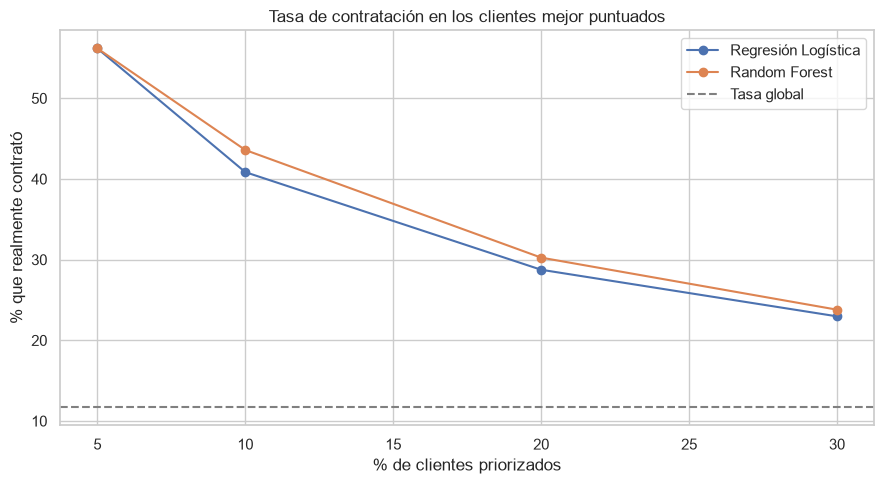

In [34]:
filas_top = []
for nombre in ["Regresión Logística", "Random Forest"]:
        # Ordenamos por score antes de contar contrataciones en los mejores percentiles.
    ranking = (pd.DataFrame({"y_real": y_test.to_numpy(),
                             "puntuacion": predicciones_finales[nombre]["proba"]})
               .sort_values("puntuacion", ascending=False))
    for pct in [5, 10, 20, 30]:
        n = int(np.ceil(len(ranking) * pct / 100))
        clientes = ranking.head(n)
        si = int(clientes["y_real"].sum())
        tasa = si / n
        filas_top.append({
            "Modelo": nombre, "Top de clientes": f"{pct}%",
            "Clientes a llamar": n, "Contrataciones": si,
            "Tasa de contratación": tasa,
            "Lift vs. promedio": tasa / y_test.mean(),
            "% de contrataciones captadas": si / y_test.sum()
        })
tabla_top = pd.DataFrame(filas_top)
display(tabla_top.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
for nombre, datos in tabla_top.groupby("Modelo", sort=False):
    ax.plot([int(p.rstrip("%")) for p in datos["Top de clientes"]],
            datos["Tasa de contratación"] * 100, marker="o", label=nombre)
ax.axhline(y_test.mean() * 100, ls="--", color="gray", label="Tasa global")
ax.set_xlabel("% de clientes priorizados")
ax.set_ylabel("% que realmente contrató")
ax.set_title("Tasa de contratación en los clientes mejor puntuados")
ax.legend()
plt.tight_layout()
plt.show()

### 9.3 ¿Cuál modelo conviene?

**La elección se hace con la validación cruzada sobre entrenamiento**, igual que los hiperparámetros: elegimos el modelo con mayor PR-AUC media de CV. El test **solo confirma** esa elección; no lo usamos para decidir.

Elección por validación cruzada — PR-AUC Logística: 0.343; Random Forest: 0.363.
Modelo elegido: Random Forest.
Confirmación en test — PR-AUC Logística: 0.357; Random Forest: 0.380 (diferencia 0.023).
El test confirma la elección hecha con validación cruzada.


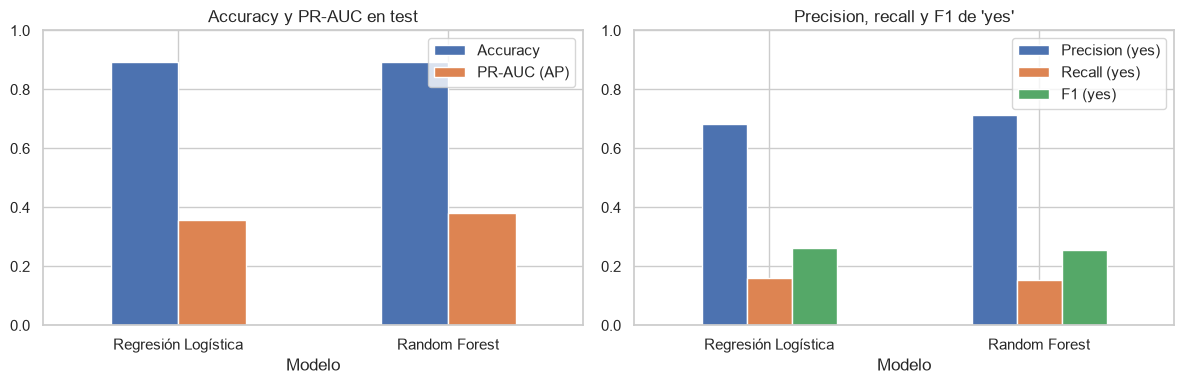

In [35]:
# 1) ELECCIÓN: con la PR-AUC media de validación cruzada (solo datos de entrenamiento).
cv_lr, cv_rf = busqueda_lr.best_score_, score_rf
mejor_modelo = "Regresión Logística" if cv_lr >= cv_rf else "Random Forest"
print(f"Elección por validación cruzada — PR-AUC Logística: {cv_lr:.3f}; Random Forest: {cv_rf:.3f}.")
print(f"Modelo elegido: {mejor_modelo}.")

# 2) CONFIRMACIÓN: miramos el test una sola vez, sin volver a ajustar nada.
pr_lr = tabla_final.loc["Regresión Logística", "PR-AUC (AP)"]
pr_rf = tabla_final.loc["Random Forest", "PR-AUC (AP)"]
diferencia_ap = abs(pr_lr - pr_rf)
mejor_en_test = "Regresión Logística" if pr_lr >= pr_rf else "Random Forest"
print(f"Confirmación en test — PR-AUC Logística: {pr_lr:.3f}; Random Forest: {pr_rf:.3f} "
      f"(diferencia {diferencia_ap:.3f}).")
if mejor_en_test == mejor_modelo:
    print("El test confirma la elección hecha con validación cruzada.")
else:
    print("En test el orden se invierte; mantenemos la elección hecha con validación cruzada.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tabla_final.loc[["Regresión Logística", "Random Forest"], ["Accuracy", "PR-AUC (AP)"]].plot.bar(
    ax=axes[0], ylim=(0, 1), title="Accuracy y PR-AUC en test", rot=0
)
tabla_final.loc[["Regresión Logística", "Random Forest"], ["Precision (yes)", "Recall (yes)", "F1 (yes)"]].plot.bar(
    ax=axes[1], ylim=(0, 1), title="Precision, recall y F1 de 'yes'", rot=0
)
plt.tight_layout()
plt.show()

---
# 10. Conclusiones

Las conclusiones se construyen **a partir de los resultados calculados en las celdas anteriores**. Así evitamos dejar porcentajes o matrices de confusión desactualizados cuando cambiamos un parámetro, la semilla o los datos.

## 10.1 Qué aprendimos de los datos

Analizamos tanto la calidad y distribución de las variables como sus diferencias entre clientes que contrataron y clientes que no. No buscamos solo correlaciones: nos interesa qué información está disponible cuando el banco tiene que decidir a quién llamar.

In [40]:
# Estadísticos de EDA calculados sobre el archivo cargado.
tasa_yes = df["y_num"].mean()
medianas_saldo = df.groupby("y")["balance"].median()
tasas_poutcome = df.groupby("poutcome", observed=True)["y_num"].mean()
tasas_housing = df.groupby("housing", observed=True)["y_num"].mean()
porcentaje_unknown = (df["poutcome"] == "unknown").mean()

# Texto final generado con cifras del archivo real: evita porcentajes escritos a mano.
texto_datos = f"""
**Qué aprendimos de los datos.** Partimos de **{len(df_raw):,} registros y {df_raw.shape[1]} columnas**. 
Después de excluir el único registro con `previous = 275`, trabajamos con **{len(df):,}**. 
Solo **{tasa_yes:.1%}** de los clientes contrató; aproximadamente **{1 - tasa_yes:.1%}** no lo hizo. 
Esta diferencia explica por qué acertar muchos `no` puede inflar la accuracy sin ayudar a encontrar contrataciones.

En el análisis numérico vimos distribuciones asimétricas, especialmente en el saldo y la cantidad de contactos. 
El saldo mediano de quienes contrataron fue **{medianas_saldo['yes']:,.0f} €**, frente a **{medianas_saldo['no']:,.0f} €** 
entre quienes no contrataron. La diferencia es descriptiva y no alcanza para predecir por sí sola. 
En el historial de campañas, el resultado `poutcome = success` tuvo una tasa de contratación de 
**{tasas_poutcome['success']:.1%}**, frente a **{tasas_poutcome['unknown']:.1%}** cuando el resultado era desconocido. 
Sin embargo, **{porcentaje_unknown:.1%}** de los registros tiene `poutcome = unknown`, por lo que no sería razonable 
construir la decisión solamente a partir del pequeño grupo con éxito previo.

También observamos diferencias según hipoteca: tasa de **{tasas_housing['no']:.1%}** para quienes no tienen 
`housing` y **{tasas_housing['yes']:.1%}** para quienes sí tienen. Eso no significa que la hipoteca cause una 
menor contratación: pueden intervenir edad, ingresos, momento de la campaña y otros factores.

En la limpieza conservamos valores negativos de saldo y categorías `unknown`, porque son parte de la información 
registrada. No usamos `duration` en el modelo porque se conoce **después de la llamada**. 
Tampoco usamos variables que describen el contacto actual para respetar la pregunta que elegimos responder: 
**a quién llamar antes de realizar ese contacto**.
"""
display(Markdown(texto_datos))


**Qué aprendimos de los datos.** Partimos de **45,211 registros y 17 columnas**. 
Después de excluir el único registro con `previous = 275`, trabajamos con **45,210**. 
Solo **11.7%** de los clientes contrató; aproximadamente **88.3%** no lo hizo. 
Esta diferencia explica por qué acertar muchos `no` puede inflar la accuracy sin ayudar a encontrar contrataciones.

En el análisis numérico vimos distribuciones asimétricas, especialmente en el saldo y la cantidad de contactos. 
El saldo mediano de quienes contrataron fue **733 €**, frente a **417 €** 
entre quienes no contrataron. La diferencia es descriptiva y no alcanza para predecir por sí sola. 
En el historial de campañas, el resultado `poutcome = success` tuvo una tasa de contratación de 
**64.7%**, frente a **9.2%** cuando el resultado era desconocido. 
Sin embargo, **81.7%** de los registros tiene `poutcome = unknown`, por lo que no sería razonable 
construir la decisión solamente a partir del pequeño grupo con éxito previo.

También observamos diferencias según hipoteca: tasa de **16.7%** para quienes no tienen 
`housing` y **7.7%** para quienes sí tienen. Eso no significa que la hipoteca cause una 
menor contratación: pueden intervenir edad, ingresos, momento de la campaña y otros factores.

En la limpieza conservamos valores negativos de saldo y categorías `unknown`, porque son parte de la información 
registrada. No usamos `duration` en el modelo porque se conoce **después de la llamada**. 
Tampoco usamos variables que describen el contacto actual para respetar la pregunta que elegimos responder: 
**a quién llamar antes de realizar ese contacto**.


## 10.2 Elección de algoritmos y parámetros

- **Regresión Lineal:** no es un clasificador. Predice un número continuo que puede ser menor que 0 o mayor que 1, así que no es una probabilidad. La incluimos como referencia, pero para un objetivo sí/no corresponde un modelo de clasificación. La Regresión Logística es justamente su versión para clasificación: aplica una sigmoide para que la salida quede entre 0 y 1.
- **KNN:** funciona con las categóricas codificadas con *one-hot*, pero tuvo la **PR-AUC más baja** de la comparación inicial. Además, con muchas columnas 0/1 las distancias son poco informativas, para predecir tiene que compararse con todos los clientes de entrenamiento y no ofrece coeficientes para interpretar.
- **Regresión Logística y Random Forest:** las elegimos por tener la mejor PR-AUC y por ser complementarias. La Logística es interpretable mediante coeficientes; Random Forest capta relaciones no lineales e interacciones.

Los hiperparámetros se eligieron por **PR-AUC media de 3 pliegues de validación cruzada**, sin consultar el test.

In [37]:
# Se leen los resultados de los objetos de búsqueda ya entrenados.
texto_ajustes = f"""
En la comparación exploratoria, los modelos iniciales obtuvieron las siguientes PR-AUC en la validación 
(separada del test): Regresión Lineal **{tabla_inicial.loc['Regresión lineal (umbral 0,5)', 'PR-AUC (AP)']:.3f}**, 
KNN **{tabla_inicial.loc['KNN (k=25)', 'PR-AUC (AP)']:.3f}**, 
Logística **{tabla_inicial.loc['Regresión logística inicial', 'PR-AUC (AP)']:.3f}** y 
Random Forest **{tabla_inicial.loc['Random Forest inicial', 'PR-AUC (AP)']:.3f}**. 
Estas cifras son orientativas porque provienen de una muestra reducida y de configuraciones iniciales.

En Logística evaluamos **{len(resultados_cv_lr)} configuraciones**. La mayor PR-AUC media de tres pliegues fue 
**{busqueda_lr.best_score_:.3f}** con **C={busqueda_lr.best_params_['clasificador__C']}** y 
**class_weight={busqueda_lr.best_params_['clasificador__class_weight']}**. 
En Random Forest probamos **{len(resultados_cv_rf)} configuraciones** de un conjunto más amplio y, con la regla de un desvío, 
elegimos la más simple entre las prácticamente empatadas: **{score_rf:.3f}** de PR-AUC media, con 
**n_estimators={params_rf['clasificador__n_estimators']}**, 
**max_depth={params_rf['clasificador__max_depth']}**, 
**min_samples_leaf={params_rf['clasificador__min_samples_leaf']}** y 
**class_weight={params_rf['clasificador__class_weight']}**. 
Con la validación cruzada, el modelo elegido es **{mejor_modelo}**.
"""
display(Markdown(texto_ajustes))


En la comparación exploratoria, los modelos iniciales obtuvieron las siguientes PR-AUC en la validación 
(separada del test): Regresión Lineal **0.368**, 
KNN **0.329**, 
Logística **0.377** y 
Random Forest **0.391**. 
Estas cifras son orientativas porque provienen de una muestra reducida y de configuraciones iniciales.

En Logística evaluamos **6 configuraciones**. La mayor PR-AUC media de tres pliegues fue 
**0.343** con **C=0.05** y 
**class_weight=None**. 
En Random Forest probamos **12 configuraciones** de un conjunto más amplio y, con la regla de un desvío, 
elegimos la más simple entre las prácticamente empatadas: **0.363** de PR-AUC media, con 
**n_estimators=80**, 
**max_depth=8**, 
**min_samples_leaf=10** y 
**class_weight=None**. 
Con la validación cruzada, el modelo elegido es **Random Forest**.


## 10.3 Resultados en test

La accuracy por sí sola puede ser engañosa cuando la mayoría no contrata. Por eso revisamos **PR-AUC**, recall y la tasa de contratación entre los clientes con puntuación más alta.

In [38]:
top10_lr = tabla_top[(tabla_top["Modelo"] == "Regresión Logística") &
                       (tabla_top["Top de clientes"] == "10%")].iloc[0]
top10_rf = tabla_top[(tabla_top["Modelo"] == "Random Forest") &
                       (tabla_top["Top de clientes"] == "10%")].iloc[0]

# Reutilizamos los mismos indicadores para describir los dos modelos sin duplicar código.
def detalle_modelo(nombre, top):
    m = tabla_final.loc[nombre]
    return (f"**{nombre}:** accuracy **{m['Accuracy']:.1%}**, precision de `yes` "
            f"**{m['Precision (yes)']:.1%}**, recall de `yes` **{m['Recall (yes)']:.1%}**, "
            f"F1 **{m['F1 (yes)']:.3f}**, ROC-AUC **{m['ROC-AUC']:.3f}** y "
            f"PR-AUC **{m['PR-AUC (AP)']:.3f}**. Entre el 10% mejor puntuado, "
            f"**{int(top['Contrataciones']):,} de {int(top['Clientes a llamar']):,}** "
            f"contrataron (**{top['Tasa de contratación']:.1%}**, lift **{top['Lift vs. promedio']:.2f}x**).")

texto_resultados = f"""
En el **test de {len(y_test):,} clientes**, de los que **{int(y_test.sum()):,}** contrataron, el predictor 
que siempre dice «no» obtuvo **{tabla_final.loc['Baseline (siempre no)', 'Accuracy']:.1%} de accuracy**, 
pero **recall 0%** para contrataciones. Es nuestro recordatorio de por qué no alcanza con mirar aciertos globales.

{detalle_modelo('Regresión Logística', top10_lr)}

{detalle_modelo('Random Forest', top10_rf)}

La diferencia de PR-AUC entre ambos fue de **{diferencia_ap:.3f} puntos**. 
Este valor refleja el test usado; no demuestra que el mismo orden se mantenga en una campaña futura.
"""
display(Markdown(texto_resultados))


En el **test de 11,303 clientes**, de los que **1,322** contrataron, el predictor 
que siempre dice «no» obtuvo **88.3% de accuracy**, 
pero **recall 0%** para contrataciones. Es nuestro recordatorio de por qué no alcanza con mirar aciertos globales.

**Regresión Logística:** accuracy **89.3%**, precision de `yes` **68.3%**, recall de `yes` **16.1%**, F1 **0.261**, ROC-AUC **0.725** y PR-AUC **0.357**. Entre el 10% mejor puntuado, **462 de 1,131** contrataron (**40.8%**, lift **3.49x**).

**Random Forest:** accuracy **89.4%**, precision de `yes` **71.4%**, recall de `yes` **15.5%**, F1 **0.255**, ROC-AUC **0.739** y PR-AUC **0.380**. Entre el 10% mejor puntuado, **493 de 1,131** contrataron (**43.6%**, lift **3.73x**).

La diferencia de PR-AUC entre ambos fue de **0.023 puntos**. 
Este valor refleja el test usado; no demuestra que el mismo orden se mantenga en una campaña futura.


## 10.4 ¿En qué se equivoca?

Los falsos negativos representan contrataciones que se omitirían usando el umbral 0,5; los falsos positivos, contactos priorizados que no terminarían en contratación. Comparamos cantidades y tasas sobre sus respectivos grupos reales. Sin costos de llamadas, no podemos convertir estos errores en pérdidas monetarias.

In [39]:
# Las conclusiones usan FN y FP efectivamente calculados sobre el test.
texto_errores = []
for nombre in ["Regresión Logística", "Random Forest"]:
    e = tabla_errores.loc[nombre]
    omitidos = e["% positivos no detectados"]
    t_falsos = e["% negativos marcados como sí"]
    texto_errores.append(
        f"**{nombre}:** {int(e['TP']):,} verdaderos positivos y {int(e['TN']):,} verdaderos negativos; "
        f"{int(e['FP']):,} falsos positivos y {int(e['FN']):,} falsos negativos. "
        f"Con umbral 0,5 dejó sin detectar **{omitidos:.1%}** de las contrataciones reales "
        f"y marcó erróneamente como positivos **{t_falsos:.1%}** de los que no contrataron."
    )

texto_final_errores = "\n\n".join(texto_errores) + """

Los **falsos negativos** muestran la principal limitación del umbral 0,5: un cliente que sí habría 
contratado puede quedar relegado. Los **falsos positivos** implican priorizar clientes que no contrataron, 
pero el costo de ese error no puede estimarse sin conocer costos por contacto y valor de cada depósito.

**El patrón principal de los errores** (apartado 9.1): con umbral 0,5, ambos modelos dicen «sí» casi exclusivamente
a clientes con `poutcome = success`. Los clientes que contrataron sin una campaña previa exitosa (`unknown`, `failure`
y `other`, la mayoría de las contrataciones) quedan **todos sin detectar**: sus características se parecen demasiado a las
de quienes no contratan, y la probabilidad estimada casi nunca llega a 0,5.

Por eso el valor del modelo no está en la respuesta sí/no, sino en el **orden**: el 10% mejor puntuado incluye muchos
clientes sin éxito previo, y entre ellos también aparecen contrataciones. Usado como ranking, el modelo va más allá
de la regla «llamar a quien ya contrató antes».
"""
display(Markdown(texto_final_errores))

**Regresión Logística:** 213 verdaderos positivos y 9,882 verdaderos negativos; 99 falsos positivos y 1,109 falsos negativos. Con umbral 0,5 dejó sin detectar **83.9%** de las contrataciones reales y marcó erróneamente como positivos **1.0%** de los que no contrataron.

**Random Forest:** 205 verdaderos positivos y 9,899 verdaderos negativos; 82 falsos positivos y 1,117 falsos negativos. Con umbral 0,5 dejó sin detectar **84.5%** de las contrataciones reales y marcó erróneamente como positivos **0.8%** de los que no contrataron.

Los **falsos negativos** muestran la principal limitación del umbral 0,5: un cliente que sí habría 
contratado puede quedar relegado. Los **falsos positivos** implican priorizar clientes que no contrataron, 
pero el costo de ese error no puede estimarse sin conocer costos por contacto y valor de cada depósito.

**El patrón principal de los errores** (apartado 9.1): con umbral 0,5, ambos modelos dicen «sí» casi exclusivamente
a clientes con `poutcome = success`. Los clientes que contrataron sin una campaña previa exitosa (`unknown`, `failure`
y `other`, la mayoría de las contrataciones) quedan **todos sin detectar**: sus características se parecen demasiado a las
de quienes no contratan, y la probabilidad estimada casi nunca llega a 0,5.

Por eso el valor del modelo no está en la respuesta sí/no, sino en el **orden**: el 10% mejor puntuado incluye muchos
clientes sin éxito previo, y entre ellos también aparecen contrataciones. Usado como ranking, el modelo va más allá
de la regla «llamar a quien ya contrató antes».


## 10.5 Limitaciones y próximos pasos

- **Validación temporal:** una campaña futura puede diferir de la muestra histórica; conviene separar entrenamiento y prueba en el tiempo.
- **Criterio comercial:** con costos por llamada y valor de cada contratación, elegir un porcentaje de clientes o un umbral según rentabilidad, usando solo validación.
- **Umbral de decisión:** elegirlo con validación cruzada (por ejemplo, para maximizar el F1 o según costos) en lugar de usar 0,5 por defecto.
- **Más información:** la duración y el resultado de llamadas *anteriores* serían variables legítimas (se conocen antes del nuevo contacto) y probablemente muy predictivas; también indicadores económicos como los de la versión `bank-additional` del dataset.
- **Datos y modelo:** evaluar la calibración de las probabilidades y la estabilidad por segmento antes de aplicarlo.

**Cierre:** los modelos ayudan a **ordenar oportunidades** de contratación antes de llamar; no garantizan que un cliente vaya a aceptar.